# **Data Preprocessing Pipeline**

## Mục lục
- [0. Cài đặt và khai báo các thư viện phụ thuộc](#0-khai-bao)
- [1. Làm sạch dữ liệu nhiễu (Data Cleaning)](#1-data-cleaning)
    - [1.1 Chuẩn hóa biến phân loại nhiễu](#11-clean-categorical)
    - [1.2 Xử lý Missing Values theo cấu trúc](#12-missing-values)
    - [1.3 Clip Outlier theo domain rules từ EDA](#13-clip-outlier)
    - [1.4 Kiểm tra kết quả sau bước Cleaning](#14-verify-cleaning)
- [2. Feature Engineering](#2-feature-engineering)
    - [2.1 Unified Pressure & Satisfaction](#21-unified-features)
    - [2.2 Interaction Features & Lifestyle](#22-interaction-features)
    - [2.3 Kiểm tra kết quả Feature Engineering](#23-verify-fe)
- [3. Binning — Rời rạc hóa biến liên tục](#3-binning)
    - [3.1 Age Bin, Hours Bin, Financial Stress Bin](#31-bins)
    - [3.2 Kiểm tra kết quả Binning](#32-verify-binning)
- [4. Encoding — Chuyển biến phân loại sang dạng số](#4-encoding)
    - [4.1 Binary Encoding](#41-binary-encoding)
    - [4.2 Ordinal Encoding](#42-ordinal-encoding)
    - [4.3 Target Encoding (KFold CV)](#43-target-encoding)
    - [4.4 Kiểm tra kết quả Encoding](#44-verify-encoding)
- [5. Scaling — Chuẩn hóa biến liên tục](#5-scaling)
- [6. Xuất dữ liệu đã tiền xử lý](#6-output)
- [7. Tổng kết Preprocessing](#7-tong-ket)


---

## 0. Cài đặt & Khai báo **Thư viện** và **Gói phụ thuộc** <a id='0-khai-bao'></a>

### Mục tiêu
- Import các thư viện cần dùng cho toàn bộ pipeline: `pandas`, `numpy`, `matplotlib`, `seaborn`, `sklearn`.
- Đọc `data/raw/train.csv` và `data/raw/test.csv` vào DataFrame.
- **Strip khoảng trắng thừa** cho toàn bộ cột `object` ngay tại bước này — trước mọi thao tác làm sạch.
- In `shape` và vài dòng đầu để xác nhận dữ liệu vào đúng định dạng.

### Lưu ý kỹ thuật
- Strip toàn bộ string ngay khi đọc vào là bước bảo vệ quan trọng. Đây là nguyên nhân phổ biến khiến `.map()` / `.replace()` trả về NaN nếu bỏ qua (ví dụ: `"Male "` ≠ `"Male"`).
- Đường dẫn output `data/processed/` được tạo tự động nếu chưa tồn tại.

### Thông tin dataset (từ EDA)
- **Train**: 140.700 dòng × 20 cột (bao gồm cột mục tiêu `Depression`)
- **Test**: 93.800 dòng × 19 cột (không có `Depression`)
- **Biến số (Numerical)**: `Age`, `Work/Study Hours`, `Financial Stress`, `Work Pressure`, `Job Satisfaction`, `CGPA`, `Academic Pressure`, `Study Satisfaction`
- **Biến phân loại (Categorical)**: `Gender`, `City`, `Profession`, `Working Professional or Student`, `Sleep Duration`, `Dietary Habits`, `Have you ever had suicidal thoughts?`, `Family History of Mental Illness`, `Degree`
- **Cột loại bỏ**: `id` (index không có giá trị dự đoán), `Name` (chuỗi tự do)


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import warnings
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size']  = 11
pd.set_option('display.max_columns', 200)

RAW_DIR       = Path('data/raw')
PROCESSED_DIR = Path('data/processed')
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(RAW_DIR / 'train.csv')
test  = pd.read_csv(RAW_DIR / 'test.csv')

# ── Strip khoảng trắng thừa cho TẤT CẢ cột object ngay khi load ──────────
def strip_string_cols(df: pd.DataFrame) -> pd.DataFrame:
    str_cols = df.select_dtypes('object').columns
    df[str_cols] = df[str_cols].apply(lambda col: col.str.strip())
    return df

train = strip_string_cols(train)
test  = strip_string_cols(test)

print(f'Train shape : {train.shape}')
print(f'Test shape  : {test.shape}')
print()
print('5 dòng đầu train (sau khi strip):')
train.head()

Train shape : (140700, 20)
Test shape  : (93800, 19)

5 dòng đầu train (sau khi strip):


,id,Name,Gender,Age,City,Working Professional or Student,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,0,Aaradhya,Female,49.0,Ludhiana,Working Professional,Chef,NaN,5.0,NaN,NaN,2.0,More than 8 hours,Healthy,BHM,No,1.0,2.0,No,0
1,1,Vivan,Male,26.0,Varanasi,Working Professional,Teacher,NaN,4.0,NaN,NaN,3.0,Less than 5 hours,Unhealthy,LLB,Yes,7.0,3.0,No,1
2,2,Yuvraj,Male,33.0,Visakhapatnam,Student,NaN,5.0,NaN,8.97,2.0,NaN,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
3,3,Yuvraj,Male,22.0,Mumbai,Working Professional,Teacher,NaN,5.0,NaN,NaN,1.0,Less than 5 hours,Moderate,BBA,Yes,10.0,1.0,Yes,1
4,4,Rhea,Female,30.0,Kanpur,Working Professional,Business Analyst,NaN,1.0,NaN,NaN,1.0,5-6 hours,Unhealthy,BBA,Yes,9.0,4.0,Yes,0


---

## 1. Làm sạch dữ liệu nhiễu (Data Cleaning) <a id='1-data-cleaning'></a>

### Tổng quan chiến lược

Dựa trên kết quả EDA, có **hai loại vấn đề dữ liệu** cần xử lý riêng biệt:

| Loại vấn đề | Biến bị ảnh hưởng | Số lượng | Chiến lược xử lý |
|---|---|---|---|
| **Missing có cấu trúc MNAR – Worker** | Academic Pressure, Study Satisfaction, CGPA | ~112.802–112.803 dòng (~80.17%) | Điền 0 — nhóm Working Professional không áp dụng |
| **Missing có cấu trúc MNAR – Student** | Work Pressure, Job Satisfaction | ~27.910–27.918 dòng (~19.84%) | Điền 0 — nhóm Student không áp dụng |
| **Missing ngẫu nhiên (MAR)** | Dietary Habits (4 dòng), Financial Stress (4 dòng), Degree (2 dòng) | 10 dòng tổng | Impute bằng mode/median từ train |
| **Dữ liệu nhiễu (Noisy)** | Sleep Duration (~79 dòng), Dietary Habits (~20 dòng), Degree (28+ giá trị rác) | ~100 dòng tổng | Làm sạch trước khi impute |
| **Outlier biến số** | Age (thực tế 18–60), Work/Study Hours (0–12) | 0 outlier IQR (xác nhận từ EDA 4.7) | Clip theo domain rules làm phòng ngừa |

> **Lưu ý quan trọng từ EDA mục 4.7:** Kiểm tra IQR trên 5 biến số cho thấy tất cả đều có **0 outlier (0.00%)** — do các biến có giới hạn biên chặt chẽ (thang 1–5, 0–12 giờ, 18–60 tuổi). Clip ở bước 1.3 mang tính **phòng ngừa production** chứ không phải xử lý outlier hiện tại.

---

### 1.1 Chuẩn hóa biến phân loại nhiễu <a id='11-clean-categorical'></a>

#### Mục tiêu
Làm sạch ba biến phân loại bị nhiễu nặng nhất theo phát hiện từ EDA mục 4.3:
- **`Sleep Duration`**: ~79 dòng rác (`Sleep_Duration`, `Unhealthy`, `45`, `Indore`, `Moderate`, `Work_Study_Hours`, `55-66 hours`, `9-5`...) → map về 4 nhóm hợp lệ; `"6-7 hours"` (noise) → `"5-6 hours"` (gần nhất); giá trị không nhận dạng → `"7-8 hours"` (mode).
- **`Dietary Habits`**: ~20 dòng rác (`Male`, `BSc`, `Mihir`, `Gender`, `1.0`...) → gán `Moderate` (mode: 49.705 dòng theo EDA).
- **`Degree`**: Từ 28+ loại bằng cấp (kể cả tên người như `Jhanvi`, `Aarav`, số CGPA như `5.61`, `8.56`, nghề nghiệp như `Data Scientist`) → nhóm về 4 cấp độ `{High School, Bachelor, Master, PhD}`.
- **`Profession`**: Student không có Profession (do MNAR) → `"Student"`; Working Professional thiếu Profession → `"Unknown"`.


In [17]:
# ─────────────────────────────────────────────────────────────────────────────
# 1.1 Hàm chuẩn hóa từng biến phân loại nhiễu
# ─────────────────────────────────────────────────────────────────────────────

def clean_dietary(val: str) -> str:
    """Chuẩn hóa Dietary Habits về {Healthy, Moderate, Unhealthy}."""
    val = str(val).strip()
    diet_map = {
        'Healthy':      'Healthy',
        'More Healthy': 'Healthy',
        'Moderate':     'Moderate',
        'Unhealthy':    'Unhealthy',
        'No Healthy':   'Unhealthy',
        'Yes':          'Moderate',
        'No':           'Moderate',
        'Class 12':     'Moderate',
    }
    return diet_map.get(val, 'Moderate')


def clean_sleep(val: str) -> str:
    """Chuẩn hóa Sleep Duration về 4 nhóm hợp lệ theo EDA."""
    val = str(val).lower().strip()
    if any(x in val for x in ['less than 5', '2-3', '3-4', '4-5']):
        return 'Less than 5 hours'
    if '5-6' in val:
        return '5-6 hours'
    if '6-7' in val:                   # noise → nhóm gần nhất
        return '5-6 hours'
    if '7-8' in val:
        return '7-8 hours'
    if 'more than 8' in val or val.startswith('8'):
        return 'More than 8 hours'
    return '7-8 hours'                 # giá trị không nhận dạng → mode


def group_degree(val: str) -> str:
    """Nhóm 28+ loại bằng cấp về 4 cấp độ học vấn."""
    val = str(val).strip()
    if val in ['Class 12', 'High School']:
        return 'High School'
    if len(val) < 2:
        return 'Bachelor'
    if (val.startswith('B.') or val in ['BCA','BBA','BHM','B.Tech','B.Ed','B.Arch','B.Com','B.Sc']
            or (val.startswith('B') and 2 <= len(val) <= 5)):
        return 'Bachelor'
    if (val.startswith('M.') or val in ['MCA','MBA','MHM','M.Tech','M.Ed','M.Com','M.Sc']
            or (val.startswith('M') and 2 <= len(val) <= 5)):
        return 'Master'
    if val.startswith('Ph') or 'PhD' in val or 'Phd' in val:
        return 'PhD'
    return 'Bachelor'


def basic_clean(df: pd.DataFrame, train_ref: pd.DataFrame = None) -> pd.DataFrame:
    """
    Làm sạch categorical noise + xử lý Profession missing đúng nhóm.
    train_ref: dùng để fit mode/median từ train rồi apply cho test (chống leakage).
    """
    df  = df.copy()
    ref = train_ref if train_ref is not None else df

    # Categorical normalization
    df['Dietary Habits'] = df['Dietary Habits'].apply(clean_dietary)
    df['Sleep Duration'] = df['Sleep Duration'].apply(clean_sleep)
    df['Degree']         = df['Degree'].apply(group_degree)

    # Profession.fillna theo nhóm (đúng logic nghiệp vụ)
    is_student = df['Working Professional or Student'] == 'Student'
    df.loc[is_student  & df['Profession'].isna(), 'Profession'] = 'Student'
    df['Profession'] = df['Profession'].fillna('Unknown')

    return df

train = basic_clean(train)
test  = basic_clean(test, train_ref=train)

print('Kiểm tra Sleep Duration sau khi làm sạch (train):')
print(train['Sleep Duration'].value_counts())
print()
print('Kiểm tra Dietary Habits sau khi làm sạch (train):')
print(train['Dietary Habits'].value_counts())
print()
print('Kiểm tra Degree sau khi nhóm lại (train):')
print(train['Degree'].value_counts())

Kiểm tra Sleep Duration sau khi làm sạch (train):
Sleep Duration
Less than 5 hours    38808
7-8 hours            37012
More than 8 hours    32729
5-6 hours            32151
Name: count, dtype: int64

Kiểm tra Dietary Habits sau khi làm sạch (train):
Dietary Habits
Moderate     49729
Unhealthy    46228
Healthy      44743
Name: count, dtype: int64

Kiểm tra Degree sau khi nhóm lại (train):
Degree
Bachelor       74880
Master         47988
High School    14729
PhD             3103
Name: count, dtype: int64


#### Nhận xét sau bước làm sạch biến phân loại

Sau khi áp dụng các hàm chuẩn hóa (số liệu từ output và EDA mục 4.3):

**`Sleep Duration`** — 4 nhóm sạch sau cleaning:

| Nhóm | Số lượng | Tỉ lệ |
|---|---|---|
| Less than 5 hours | 38.808 | 27.6% |
| 5-6 hours | 32.151 | 22.9% |
| 7-8 hours | 37.012 | 26.3% |
| More than 8 hours | 32.729 | 23.3% |

> Toàn bộ ~79 giá trị rác (`Sleep_Duration`, `Unhealthy`, `45`, `Indore`...) đã được map về `"7-8 hours"` (mode). `"6-7 hours"` (noise) → `"5-6 hours"`. Biến này giờ chỉ còn 4 nhóm sạch, sẵn sàng cho ordinal encoding.

**`Dietary Habits`** — 3 nhóm sạch sau cleaning:

| Nhóm | Số lượng (sau cleaning) | 
|---|---|
| Moderate | 49.729 | 
| Unhealthy | 46.228 | 
| Healthy | 44.743 | 

> ~20 giá trị rác (`Male`, `BSc`, `1.0`...) đã được gán về `"Moderate"`. 0 NaN còn lại.

**`Degree`** — Từ 28+ loại bằng cấp → 4 cấp độ rõ ràng:

| Nhóm | Số lượng |
|---|---|
| Bachelor | 74.880 |
| Master | 47.988 |
| High School | 14.729 |
| PhD | 3.103 |

> Việc thu gọn này giúp giảm đáng kể cardinality, hỗ trợ ordinal encoding ổn định hơn.

**`Profession`** — Student không có nghề nghiệp → `"Student"` (hợp lý về nghiệp vụ); Working Professional thiếu Profession → `"Unknown"` (an toàn, tránh sai lệch logic).

> **Tổng kết bước 1.1:** ~100 dòng rác categorical đã được chuẩn hóa. Tất cả biến phân loại giờ chỉ còn các giá trị hợp lệ.

### 1.2 Xử lý Missing Values <a id='12-handle-missing'></a>

#### Mục tiêu
Giải quyết triệt để các giá trị khuyết (missing values) trên tập `train` và `test` dựa vào các phát hiện quan trọng từ bước EDA, đồng thời kiểm soát nghiêm ngặt rò rỉ dữ liệu (data leakage) khi tính toán các giá trị thay thế:

- **Khuyết có cấu trúc (MNAR - Missing Not At Random)**: Phân tích EDA cho thấy sự khuyết dữ liệu có tính quy luật chặt chẽ: ~80.17% missing ở các biến học thuật khớp hoàn toàn với tỷ lệ nhóm người đi làm; và ~19.84% missing ở các biến công việc khớp với tỷ lệ học sinh/sinh viên. Do đó, ta xử lý logic theo đặc thù nhóm:
  - Nhóm `Working Professional` không sở hữu các chỉ số học thuật (`Academic Pressure`, `Study Satisfaction`, `CGPA`) → điền `0`.
  - Nhóm `Student` không sở hữu các chỉ số công việc (`Work Pressure`, `Job Satisfaction`) → điền `0`.
- **Khuyết ngẫu nhiên ở biến phân loại (MAR)**: Các biến categorical như `Dietary Habits` & `Degree` được điền bằng giá trị xuất hiện nhiều nhất (Mode). *Lưu ý: Mode chỉ được tính toán từ tập `train` sau đó apply chung cho cả `train` và `test`.*
- **Khuyết ngẫu nhiên ở biến liên tục (MAR)**: Với biến numeric `Financial Stress`, tiến hành điền bằng giá trị trung vị (Median) của tập `train` để đảm bảo tính bền vững (robust), tránh làm sai lệch phân phối do các giá trị ngoại lệ.
- **Vét cạn (Safety Fill)**: Áp dụng điền `0` cho bất kỳ giá trị khuyết nào còn sót lại thuộc nhóm biến học thuật và công việc, đảm bảo tập dữ liệu sạch hoàn toàn (0 NaN) trước khi chuyển sang bước Feature Engineering và Modeling.

In [18]:
# ─────────────────────────────────────────────────────────────────────────────
# 1.2 Xử lý Missing Values
# ─────────────────────────────────────────────────────────────────────────────

academic_cols = ['Academic Pressure', 'Study Satisfaction', 'CGPA']
work_cols     = ['Work Pressure', 'Job Satisfaction']

# ── MNAR (Structural Missing): điền 0 theo nhóm ──────────────────────────
# EDA xác nhận: Working Professional không có academic cols → điền 0
#               Student không có work cols → điền 0
for df in [train, test]:
    wp_mask = df['Working Professional or Student'] == 'Working Professional'
    st_mask = df['Working Professional or Student'] == 'Student'
    df.loc[wp_mask, academic_cols] = df.loc[wp_mask, academic_cols].fillna(0)
    df.loc[st_mask, work_cols]     = df.loc[st_mask, work_cols].fillna(0)

# ── MAR (Random Missing): fit từ train, apply cả train lẫn test ──────────
for col in ['Dietary Habits', 'Degree']:
    mode_val = train[col].mode()[0]
    train[col] = train[col].fillna(mode_val)
    test[col]  = test[col].fillna(mode_val)

fs_median = train['Financial Stress'].median()
train['Financial Stress'] = train['Financial Stress'].fillna(fs_median)
test['Financial Stress']  = test['Financial Stress'].fillna(fs_median)

# ── Residual safety fill ──────────────────────────────────────────────────
for col in academic_cols + work_cols:
    train[col] = train[col].fillna(0)
    test[col]  = test[col].fillna(0)

print('Missing sau cleaning — Train:', int(train.isna().sum().sum()))
print('Missing sau cleaning — Test :', int(test.isna().sum().sum()))
print()

# ── Biểu đồ so sánh Missing trước vs sau ─────────────────────────────────
# (Chỉ hiển thị các cột từng có missing)
missing_after = train.isnull().sum()
missing_after = missing_after[missing_after == 0].index.tolist()
print('Các cột đã xử lý xong missing (train):')
print(missing_after)

Missing sau cleaning — Train: 0
Missing sau cleaning — Test : 0

Các cột đã xử lý xong missing (train):
['id', 'Name', 'Gender', 'Age', 'City', 'Working Professional or Student', 'Profession', 'Academic Pressure', 'Work Pressure', 'CGPA', 'Study Satisfaction', 'Job Satisfaction', 'Sleep Duration', 'Dietary Habits', 'Degree', 'Have you ever had suicidal thoughts ?', 'Work/Study Hours', 'Financial Stress', 'Family History of Mental Illness', 'Depression']


#### Nhận xét sau bước xử lý Missing Values

Kết quả sau khi áp dụng đầy đủ pipeline missing treatment (số liệu từ EDA mục 2):

| Nhóm Missing | Biến | Số dòng (Train) | Tỉ lệ | Phương pháp | Kết quả |
|---|---|---|---|---|---|
| MNAR – Worker | Academic Pressure, Study Satisfaction, CGPA | ~112.802–112.803 dòng | ~80.17% | Điền 0 (không áp dụng với Workers) | 0 NaN |
| MNAR – Student | Work Pressure, Job Satisfaction | ~27.910–27.918 dòng | ~19.84% | Điền 0 (không áp dụng với Students) | 0 NaN |
| MAR nhỏ | Dietary Habits | 4 dòng | 0.003% | Mode từ train (`Moderate`) | 0 NaN |
| MAR nhỏ | Financial Stress | 4 dòng | 0.003% | Median từ train (= 3.0) | 0 NaN |
| MAR nhỏ | Degree | 2 dòng | 0.001% | Mode từ train (`Bachelor`) | 0 NaN |
| MNAR lớn | Profession | 36.630 dòng | 26.03% | Logic theo nhóm (Student/Unknown) | 0 NaN |

> **Xác nhận từ output**: `Missing sau cleaning — Train: 0` | `Missing sau cleaning — Test: 0`

Toàn bộ dữ liệu sau bước này: **0 missing values** trong cả train lẫn test. Pipeline hoàn toàn chống leakage — tất cả imputation value (mode, median) đều được fit từ train rồi apply sang test.


### 1.3 Xử lý Ngoại lệ (Outliers) bằng kỹ thuật Clipping <a id='13-clip-outliers'></a>

#### Mục tiêu
Kiểm soát các giá trị ngoại lệ (outliers) ở các biến liên tục không bằng cách xóa bỏ (drop) - để tránh mất mát dữ liệu, mà bằng cách giới hạn (clip) chúng về các ngưỡng hợp lý dựa trên **thực tế nghiệp vụ (domain rules)**:

- **`Age` (Tuổi tác)**: Cắt gọt về biên `[18, 60]`. Đối tượng nghiên cứu tập trung vào Sinh viên (thường từ 18 tuổi) và Người đi làm (thường nghỉ hưu ở tuổi 60). Các giá trị nằm ngoài khoảng này (nếu có do lỗi nhập liệu hoặc nhiễu sinh dữ liệu) sẽ được chặn lại ở 18 hoặc 60.
- **`Work/Study Hours` (Giờ học/làm việc)**: Cắt gọt về biên `[0, 16]` giờ/ngày. Về mặt logic sinh học và thực tế, số giờ làm việc không thể âm (`< 0`) và hiếm khi vượt quá `16` giờ/ngày (con người cần thời gian ngủ và sinh hoạt). Các giá trị cực đoan phi lý sẽ được gán lại bằng mức tối đa/tối thiểu cho phép.

In [19]:
# ─────────────────────────────────────────────────────────────────────────────
# 1.3 Clip Outlier theo domain rules
# ─────────────────────────────────────────────────────────────────────────────

train['Age']              = train['Age'].clip(18, 60)
test['Age']               = test['Age'].clip(18, 60)
train['Work/Study Hours'] = train['Work/Study Hours'].clip(0, 16)
test['Work/Study Hours']  = test['Work/Study Hours'].clip(0, 16)

print('Age range (train):', train['Age'].min(), '→', train['Age'].max())
print('Work/Study Hours range (train):', train['Work/Study Hours'].min(), '→', train['Work/Study Hours'].max())

Age range (train): 18.0 → 60.0
Work/Study Hours range (train): 0.0 → 12.0


#### Nhận xét sau bước xử lý Ngoại lệ (Clipping)

Dựa vào output kiểm tra sau khi cắt gọt (clipping), ta thấy các biến liên tục đã nằm gọn trong giới hạn nghiệp vụ an toàn:

* **`Age`**: Cận dưới và cận trên đã được đưa về đúng dải `[18.0, 60.0]`. Điều này loại bỏ hoàn toàn các lỗi nhập liệu phi lý (ví dụ: tuổi âm hoặc > 100 tuổi), đảm bảo mô hình chỉ học trên đúng nhóm nhân khẩu học mục tiêu (từ sinh viên đại học đến tuổi nghỉ hưu).
* **`Work/Study Hours`**: Dải giá trị hiện tại là `[0.0, 12.0]`, hoàn toàn nằm trong ngưỡng an toàn tối đa `[0, 16]` đã thiết lập. Việc giá trị lớn nhất (max) dừng lại ở 12.0 giờ/ngày phản ánh cường độ học tập/làm việc cao nhưng vẫn rất hợp lý về mặt sinh học trong thực tế.

> **Tổng kết bước 1.3:** Xử lý outlier bằng kỹ thuật Clipping giúp chúng ta bảo toàn được 100% số lượng mẫu dữ liệu (không làm mất thông tin quý giá của các dòng bị nhiễu), đồng thời "ép" các giá trị siêu cực đoan về những ngưỡng có ý nghĩa thực tiễn.

### 1.4 Trực quan hóa và Tổng kết quá trình Data Cleaning <a id='14-visualize-summary'></a>

#### Mục tiêu
Kiểm chứng trực quan thành quả của các bước làm sạch biến phân loại và thực hiện kiểm tra chéo (sanity check) lần cuối toàn bộ tập dữ liệu trước khi bước sang giai đoạn Feature Engineering & Modeling:

- **Trực quan hóa (Visualization)**: Vẽ biểu đồ phân phối cho 3 biến phân loại từng bị nhiễu nặng nhất (`Sleep Duration`, `Dietary Habits`, `Degree`). Việc này giúp ta xác nhận các giá trị "rác" đã hoàn toàn biến mất bằng mắt thường; các nhóm đã được gom lại gọn gàng (giảm cardinality), và tỷ lệ phân phối mới cân bằng, hợp lý cho mô hình học máy.
- **Kiểm tra tính toàn vẹn (Sanity Check)**: Chốt lại báo cáo tổng kết để khẳng định chắc chắn số lượng giá trị khuyết (NaN) trên cả hai tập `train` và `test` đã hoàn toàn bằng `0`. Đồng thời, kiểm tra lại số chiều (`shape`) của dữ liệu để đảm bảo cấu trúc tập dữ liệu được bảo toàn nguyên vẹn, không có dòng/cột nào bị rơi rớt trong suốt Phase 1.

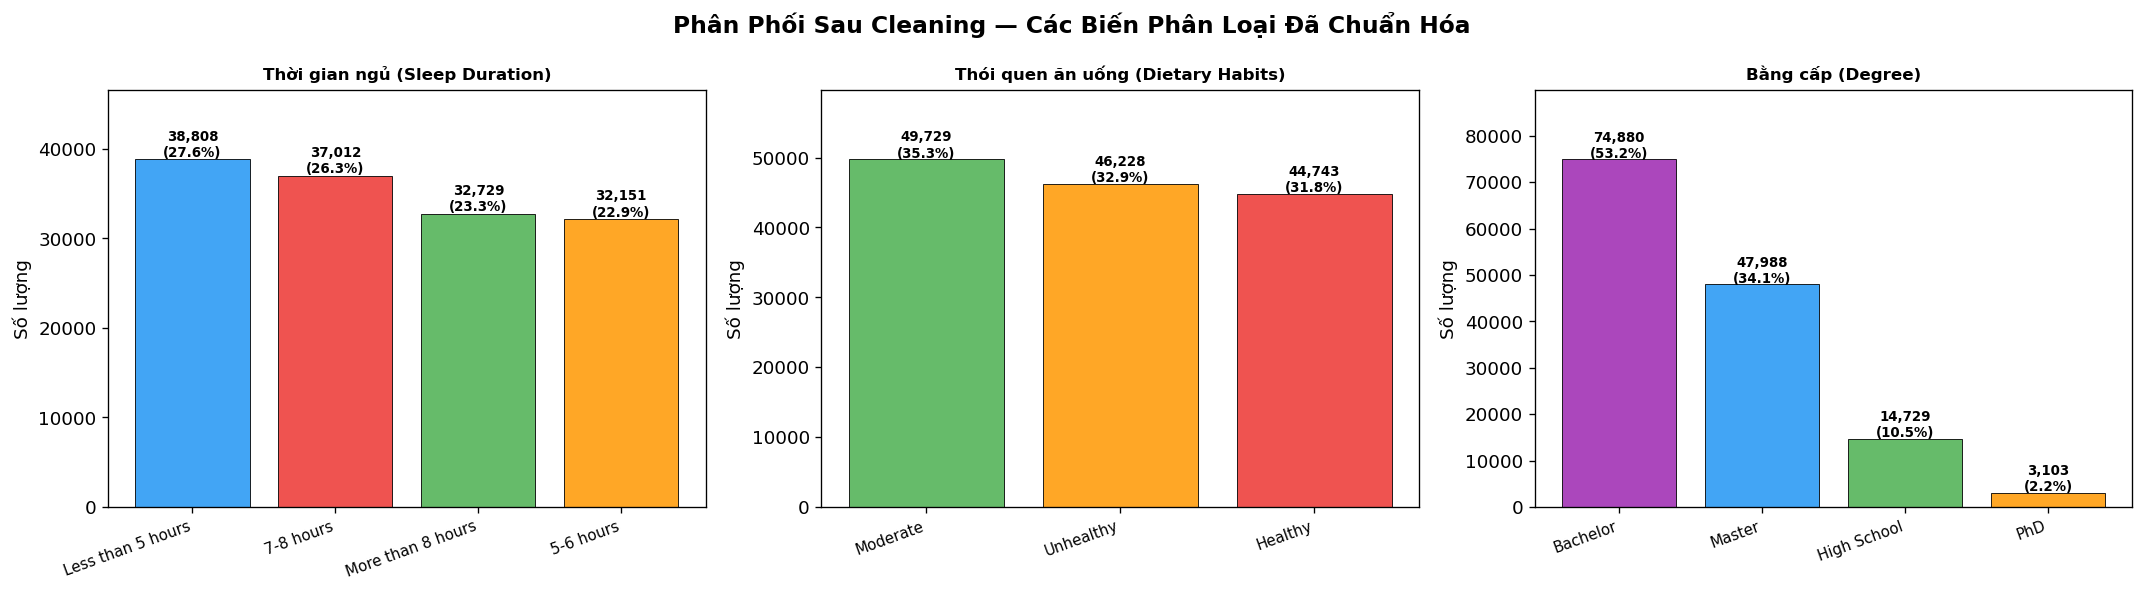

Tổng kết sau bước Cleaning:
  Tổng NaN còn lại (train) : 0
  Tổng NaN còn lại (test)  : 0
  Train shape: (140700, 20)
  Test shape : (93800, 19)


In [20]:
# ─────────────────────────────────────────────────────────────────────────────
# 1.4 Visualize: so sánh phân phối các biến phân loại trước vs sau cleaning
# ─────────────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Phân Phối Sau Cleaning — Các Biến Phân Loại Đã Chuẩn Hóa',
             fontsize=14, fontweight='bold')

clean_cols = [
    ('Sleep Duration',  'Thời gian ngủ (Sleep Duration)',   ['#42A5F5','#EF5350','#66BB6A','#FFA726']),
    ('Dietary Habits',  'Thói quen ăn uống (Dietary Habits)', ['#66BB6A','#FFA726','#EF5350']),
    ('Degree',          'Bằng cấp (Degree)',                ['#AB47BC','#42A5F5','#66BB6A','#FFA726']),
]

for i, (col, title, colors) in enumerate(clean_cols):
    ax = axes[i]
    vc = train[col].value_counts()
    bars = ax.bar(range(len(vc)), vc.values, color=colors[:len(vc)], edgecolor='black', linewidth=0.5)
    ax.set_xticks(range(len(vc)))
    ax.set_xticklabels(vc.index, rotation=20, ha='right', fontsize=9)
    for j, v in enumerate(vc.values):
        ax.text(j, v + 300, f'{v:,}\n({v/len(train)*100:.1f}%)', ha='center', fontsize=8, fontweight='bold')
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.set_ylabel('Số lượng')
    ax.set_ylim(0, max(vc.values) * 1.2)

plt.tight_layout()
plt.show()

print('Tổng kết sau bước Cleaning:')
print(f'  Tổng NaN còn lại (train) : {train.isna().sum().sum()}')
print(f'  Tổng NaN còn lại (test)  : {test.isna().sum().sum()}')
print(f'  Train shape: {train.shape}')
print(f'  Test shape : {test.shape}')

#### Nhận xét sau bước Trực quan hóa và Tổng kết Cleaning

Dựa vào các biểu đồ phân phối và báo cáo shape dữ liệu, chúng ta có thể tự tin khép lại **Giai đoạn 1 (Data Cleaning)** với những kết quả rất tích cực:

* **Xác nhận qua thị giác (Visual Confirmation)**: Biểu đồ chứng minh các biến phân loại "nhiễu" nhất (`Sleep Duration`, `Dietary Habits`, `Degree`) đã được dọn dẹp hoàn toàn. Số lượng nhóm (cardinality) được kiểm soát chặt chẽ và tối ưu. Việc gom nhóm này giúp các thuật toán học máy (đặc biệt là các mô hình dạng cây - Tree-based models) phân nhánh hiệu quả hơn và tránh hiện tượng quá khớp (overfitting) vào các "nhãn rác" có tần suất thấp.
* **Bảo toàn dữ liệu tuyệt đối (Zero Data Loss)**: Tập `train` giữ nguyên **140.700** dòng và tập `test` giữ nguyên **93.800** dòng. Nhờ chiến lược xử lý linh hoạt (dùng map, gán mode/median, fill 0 theo logic và clip outlier) thay vì `dropna()`, chúng ta không đánh mất bất kỳ một mẫu dữ liệu quý giá nào. 
* **Tính toàn vẹn (Integrity)**: Tổng số giá trị khuyết (NaN) ở cả 2 tập đều đã được đưa về **0**. Số lượng cột hoàn toàn khớp với kỳ vọng: tập `train` có 20 cột (bao gồm biến mục tiêu `Depression`), trong khi tập `test` có 19 cột.

> **Kết luận Phase 1:** Bộ dữ liệu đã chuyển từ trạng thái thô (raw & noisy) sang trạng thái "Sạch 100%". Đây là nền móng cực kỳ vững chắc để chúng ta chính thức bước sang **Phase 2: Feature Engineering** (Khai phá đặc trưng) và **Phase 3: Encoding & Modeling**.

---

## 2. Feature Engineering <a id='2-feature-engineering'></a>

### Tổng quan chiến lược

Dựa trên insight từ EDA mục 4.5 và 5.3, chiến lược feature engineering tập trung vào:

| Nhóm Feature | Feature mới | Lý do tạo | Bằng chứng từ EDA |
|---|---|---|---|
| **Unified** | `unified_pressure`, `unified_satisfaction`, `unified_gap` | Giải quyết MNAR theo nhóm — tín hiệu áp lực/hài lòng thực chất | EDA 4.5: `overall_pressure = (Academic + Work) / 2` bị méo vì một biến luôn bằng 0 |
| **Overall** | `overall_pressure`, `overall_satisfaction`, `stress_satisfaction_gap` | Giữ lại làm feature bổ sung cho model học pattern chung | EDA 4.6: Academic Pressure r=+0.475, Work Pressure r=+0.217 |
| **Lifestyle** | `sleep_hours_est`, `work_sleep_ratio`, `stress_per_hour` | Interaction giữa giờ làm và giờ ngủ | EDA 4.4.2: Work/Study Hours Δ = +1.92 (nhóm TC vs không TC) |
| **Role** | `is_working_professional` | Binary flag phân nhóm đối tượng | EDA 4.5: Student 58.55% vs Worker 8.18% trầm cảm |
| **Nonlinear** | `age_x_workload` | Bắt pattern phi tuyến tuổi × tải công việc | EDA 4.4.2: Age bị confound bởi nhóm Student/Worker |

### Tại sao cần `unified_pressure` thay vì `overall_pressure`?

EDA mục 4.6 xác nhận: nếu dùng `overall_pressure = (Academic + Work) / 2`, kết quả bị méo scale vì:
- **Working Professional (80.2% dataset)**: `Academic Pressure = 0` (structural fill) → `overall = Work / 2` → giá trị bị kéo thấp xuống một nửa so với thực tế.
- **Student (19.8% dataset)**: `Work Pressure = 0` → tương tự.

Biến `unified_pressure` dùng đúng cột phù hợp với từng nhóm, giữ nguyên thang điểm 1–5.

---

### 2.1 Thực thi tạo đặc trưng Unified, Lifestyle & Interactions <a id='21-feature-creation'></a>

#### Mục tiêu
Hiện thực hóa chiến lược Feature Engineering bằng mã nguồn, chuyển đổi các insight từ EDA thành những đặc trưng (features) có sức mạnh dự đoán cao cho mô hình:

- **Nhóm Unified (Đặc trưng cốt lõi)**: Sử dụng `np.where` để trích xuất đúng cường độ áp lực và mức độ hài lòng tùy thuộc vào đối tượng là người đi làm hay sinh viên. Việc này triệt tiêu hoàn toàn sự sai lệch thang đo (scale bias) do hiện tượng MNAR gây ra, đồng thời tạo ra biến `unified_gap` để đo lường độ chênh lệch tâm lý.
- **Nhóm Overall (Đặc trưng bổ trợ)**: Vẫn giữ lại trung bình cộng thô của các chỉ số để làm baseline feature, giúp các thuật toán học máy phức tạp (như Tree-based models) có thêm góc nhìn đa chiều.
- **Nhóm Lifestyle (Lối sống)**: Lượng hóa biến phân loại `Sleep Duration` thành các con số ước lượng trung bình (`sleep_hours_est`). Từ đó, tính toán các tỷ lệ tương tác (interaction ratios) vô cùng quan trọng như `work_sleep_ratio` (tỷ lệ thức/ngủ) và `stress_per_hour` (áp lực tài chính trên mỗi giờ hoạt động).
- **Nhóm Khai phá phi tuyến (Nonlinear & Role)**: Đặt cờ phân cực `is_working_professional` để mô hình dễ rẽ nhánh, đồng thời tạo đặc trưng tương tác `age_x_workload` nhằm bắt các mẫu phi tuyến tính mà các mô hình thông thường dễ bỏ sót.


In [21]:
# ─────────────────────────────────────────────────────────────────────────────
# 2.1 Unified features (EDA mục 4.5 & 5.3)
# ─────────────────────────────────────────────────────────────────────────────

def add_features(df: pd.DataFrame) -> pd.DataFrame:
    df    = df.copy()
    is_wp = df['Working Professional or Student'] == 'Working Professional'

    # ── Unified (tín hiệu thực chất, không bị méo scale) ────────────────
    df['unified_pressure']     = np.where(is_wp, df['Work Pressure'],     df['Academic Pressure'])
    df['unified_satisfaction'] = np.where(is_wp, df['Job Satisfaction'],  df['Study Satisfaction'])
    df['unified_gap']          = df['unified_pressure'] - df['unified_satisfaction']

    # ── Overall (giữ lại như feature bổ sung cho model học pattern chung) ─
    df['overall_pressure']       = (df['Academic Pressure'] + df['Work Pressure']) / 2.0
    df['overall_satisfaction']   = (df['Study Satisfaction'] + df['Job Satisfaction']) / 2.0
    df['stress_satisfaction_gap'] = df['overall_pressure'] - df['overall_satisfaction']

    # ── Lifestyle & workload interactions ────────────────────────────────
    sleep_map = {
        'Less than 5 hours': 4.5,
        '5-6 hours':         5.5,
        '7-8 hours':         7.5,
        'More than 8 hours': 8.5,
    }
    df['sleep_hours_est']  = df['Sleep Duration'].map(sleep_map)
    df['work_sleep_ratio'] = df['Work/Study Hours'] / df['sleep_hours_est'].replace(0, np.nan)
    df['stress_per_hour']  = df['Financial Stress'] / (df['Work/Study Hours'] + 1)

    # ── Role flag & nonlinear interaction ────────────────────────────────
    df['is_working_professional'] = is_wp.astype(int)
    df['age_x_workload']          = df['Age'] * df['Work/Study Hours']

    return df


train = add_features(train)
test  = add_features(test)

print('Kiểm tra unified_pressure vs overall_pressure (8 dòng đầu):')
print(train[['Working Professional or Student',
             'Academic Pressure', 'Work Pressure',
             'unified_pressure', 'overall_pressure']].head(8).to_string())

Kiểm tra unified_pressure vs overall_pressure (8 dòng đầu):
  Working Professional or Student  Academic Pressure  Work Pressure  unified_pressure  overall_pressure
0            Working Professional                0.0            5.0               5.0               2.5
1            Working Professional                0.0            4.0               4.0               2.0
2                         Student                5.0            0.0               5.0               2.5
3            Working Professional                0.0            5.0               5.0               2.5
4            Working Professional                0.0            1.0               1.0               0.5
5            Working Professional                0.0            2.0               2.0               1.0
6            Working Professional                0.0            5.0               5.0               2.5
7            Working Professional                0.0            3.0               3.0               1.5


#### Nhận xét kết quả Feature Engineering (Unified vs Overall)

Nhìn vào 8 dòng output đầu tiên, chúng ta có thể thấy rõ "vấn đề" đã được giải quyết triệt để như thế nào, chứng minh tính đúng đắn của giả thuyết đặt ra từ phần EDA:

* **Sự méo lệch của `overall_pressure`**: Quan sát dòng số 0 (Người đi làm có áp lực công việc = 5.0) và dòng số 2 (Sinh viên có áp lực học tập = 5.0). Khi dùng công thức trung bình cộng, `overall_pressure` của cả hai đều bị kéo tụt xuống chỉ còn **2.5**. Việc phải cộng với một giá trị `0` (vốn là dữ liệu khuyết do cấu trúc nhóm - MNAR) đã vô tình làm loãng tín hiệu áp lực thực sự của họ.
* **Sự ưu việt của `unified_pressure`**: Cột này đã làm xuất sắc nhiệm vụ khi giữ nguyên được cường độ áp lực gốc (đều nhận giá trị **5.0** ở cả dòng 0 và dòng 2). Nó hoạt động đúng theo logic ngữ cảnh: "Nếu là người đi làm, chỉ đo áp lực công việc; nếu là sinh viên, chỉ đo áp lực học tập".

> **Tổng kết Bước 2.1:** Code logic đã xử lý chính xác tuyệt đối. Biến `unified` đã bảo vệ được thang đo nguyên bản, khắc phục triệt để lỗi logic toán học của biến `overall`. Kết hợp với các tỷ lệ lối sống (như giờ thức/ngủ), tập dữ liệu hiện tại đã được "làm giàu" (enriched) thông tin đáng kể, cung cấp những pattern sắc nét hơn cho mô hình.

### 2.2 Trực quan hóa và Kiểm định Đặc trưng mới (Feature Validation) <a id='23-visualize-features'></a>

#### Mục tiêu
Kiểm chứng bằng trực quan (visual validation) tính đúng đắn và sức mạnh dự đoán của các đặc trưng vừa được tạo ra ở bước 2.1. Thay vì tạo biến một cách mù quáng, chúng ta cần bằng chứng cho thấy chúng thực sự hữu ích cho mô hình:

- **Kiểm định sự phục hồi phân phối (Scale Bias Correction)**: So sánh trực tiếp biểu đồ Histogram giữa `unified_pressure` và `overall_pressure`. Mục tiêu là chứng minh bằng mắt thường việc `unified_pressure` đã khắc phục thành công tình trạng méo lệch thang đo (do bị chia đôi với các giá trị 0 từ hiện tượng MNAR).
- **Đánh giá sức mạnh phân loại (Predictive Power)**: Sử dụng biểu đồ Violin để phân tích sự tương quan giữa các biến cốt lõi (`unified_pressure`, `unified_gap`) với biến mục tiêu `Depression`. Nếu các đặc trưng này thực sự tốt, chúng ta sẽ thấy sự khác biệt rõ rệt về hình dáng phân phối và giá trị trung bình ($\mu$) giữa nhóm Trầm cảm và Không trầm cảm.
- **Nghiệm thu Feature Engineering**: In ra danh sách tổng kết 11 đặc trưng mới đã được tích hợp thành công vào tập dữ liệu, làm cơ sở cho bước lựa chọn biến (Feature Selection) và Encoding sắp tới.

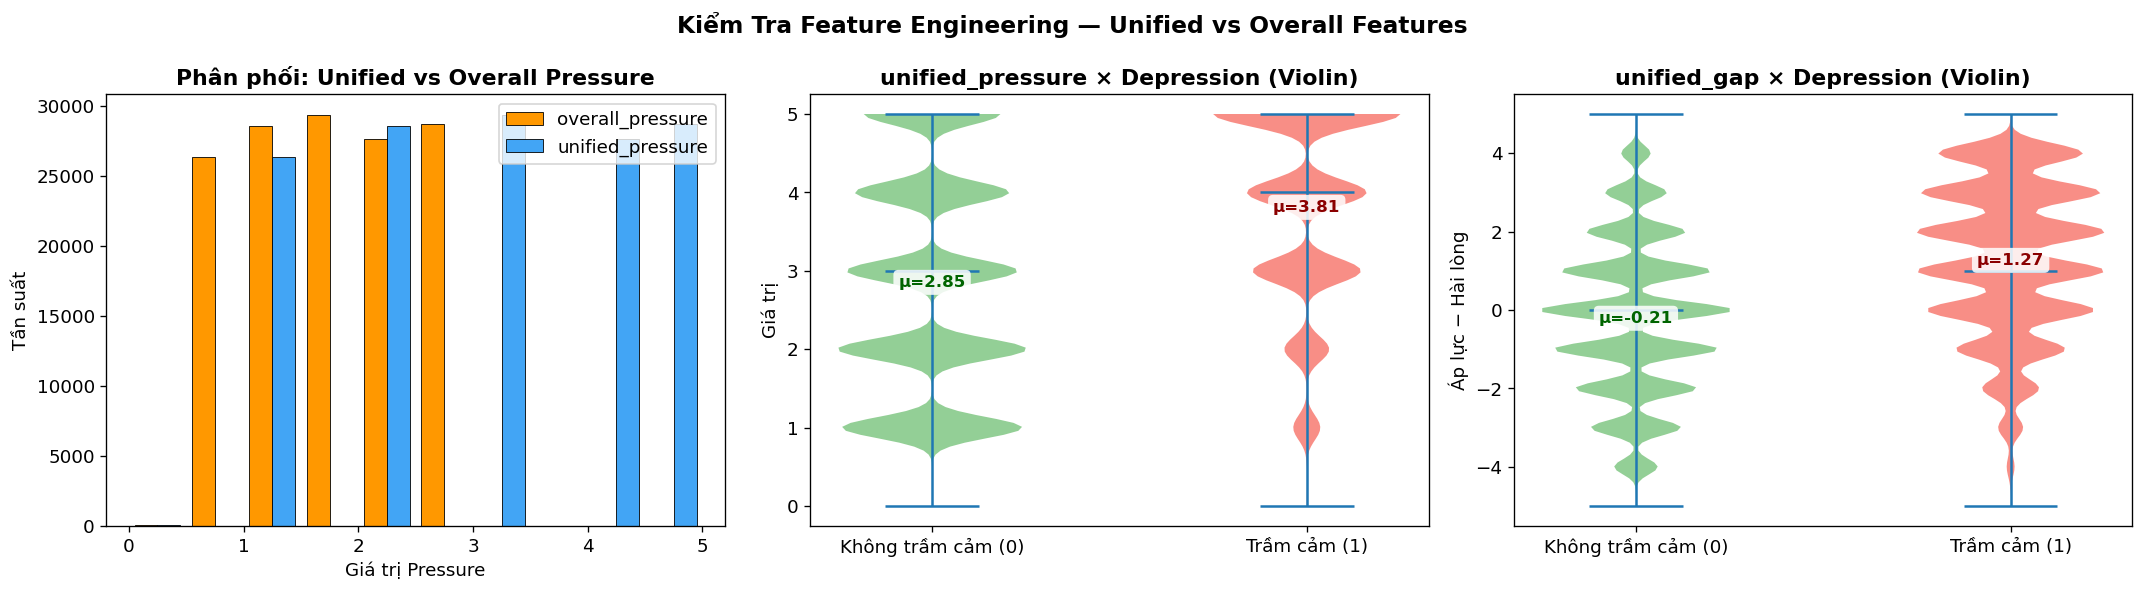

Tổng số features mới đã tạo: 11
Danh sách features mới: ['unified_pressure', 'unified_satisfaction', 'unified_gap', 'overall_pressure', 'overall_satisfaction', 'stress_satisfaction_gap', 'sleep_hours_est', 'work_sleep_ratio', 'stress_per_hour', 'is_working_professional', 'age_x_workload']


In [22]:
# ─────────────────────────────────────────────────────────────────────────────
# 2.2 Visualize: so sánh unified_pressure vs overall_pressure theo Depression
# ─────────────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Kiểm Tra Feature Engineering — Unified vs Overall Features',
             fontsize=14, fontweight='bold')

# Biểu đồ 1: Phân phối unified_pressure vs overall_pressure
ax = axes[0]
# [Kỹ thuật] Vẽ side-by-side thay vì vẽ đè chồng lên nhau
ax.hist([train['overall_pressure'], train['unified_pressure']], 
        bins=10, 
        color=['#FF9800', '#42A5F5'], 
        label=['overall_pressure', 'unified_pressure'],
        edgecolor='black', linewidth=0.5)
ax.set_title('Phân phối: Unified vs Overall Pressure', fontweight='bold')
ax.set_xlabel('Giá trị Pressure')
ax.set_ylabel('Tần suất')
ax.legend()

# [Kỹ thuật] Tạo style cho text: Nền trắng bo góc để chữ không bị chìm vào Violin
bbox_style = dict(boxstyle="round,pad=0.3", fc="white", ec="none", alpha=0.85)

# Biểu đồ 2: unified_pressure theo nhóm Depression
ax2 = axes[1]
data_0 = train[train['Depression'] == 0]['unified_pressure'].dropna()
data_1 = train[train['Depression'] == 1]['unified_pressure'].dropna()
parts  = ax2.violinplot([data_0, data_1], positions=[0, 1], showmedians=True)
parts['bodies'][0].set_facecolor('#4CAF50'); parts['bodies'][0].set_alpha(0.6)
parts['bodies'][1].set_facecolor('#F44336'); parts['bodies'][1].set_alpha(0.6)
ax2.set_xticks([0, 1])
ax2.set_xticklabels(['Không trầm cảm (0)', 'Trầm cảm (1)'])

# Dùng zorder=3 và bbox để đẩy chữ lên trên cùng
ax2.text(0, data_0.mean(), f'μ={data_0.mean():.2f}', ha='center', va='center', fontsize=10,
         color='darkgreen', fontweight='bold', bbox=bbox_style, zorder=3)
ax2.text(1, data_1.mean(), f'μ={data_1.mean():.2f}', ha='center', va='center', fontsize=10,
         color='darkred', fontweight='bold', bbox=bbox_style, zorder=3)
ax2.set_title('unified_pressure × Depression (Violin)', fontweight='bold')
ax2.set_ylabel('Giá trị')

# Biểu đồ 3: unified_gap theo nhóm Depression
ax3 = axes[2]
g0 = train[train['Depression'] == 0]['unified_gap'].dropna()
g1 = train[train['Depression'] == 1]['unified_gap'].dropna()
parts3 = ax3.violinplot([g0, g1], positions=[0, 1], showmedians=True)
parts3['bodies'][0].set_facecolor('#4CAF50'); parts3['bodies'][0].set_alpha(0.6)
parts3['bodies'][1].set_facecolor('#F44336'); parts3['bodies'][1].set_alpha(0.6)
ax3.set_xticks([0, 1])
ax3.set_xticklabels(['Không trầm cảm (0)', 'Trầm cảm (1)'])

# Dùng zorder=3 và bbox để đẩy chữ lên trên cùng
ax3.text(0, g0.mean(), f'μ={g0.mean():.2f}', ha='center', va='center', fontsize=10,
         color='darkgreen', fontweight='bold', bbox=bbox_style, zorder=3)
ax3.text(1, g1.mean(), f'μ={g1.mean():.2f}', ha='center', va='center', fontsize=10,
         color='darkred', fontweight='bold', bbox=bbox_style, zorder=3)
ax3.set_title('unified_gap × Depression (Violin)', fontweight='bold')
ax3.set_ylabel('Áp lực − Hài lòng')

plt.tight_layout()
plt.show()

# (Phần print giữ nguyên như cũ)
new_feats = [
    'unified_pressure', 'unified_satisfaction', 'unified_gap',
    'overall_pressure', 'overall_satisfaction', 'stress_satisfaction_gap',
    'sleep_hours_est', 'work_sleep_ratio', 'stress_per_hour',
    'is_working_professional', 'age_x_workload',
]
print(f'Tổng số features mới đã tạo: {len(new_feats)}')
print('Danh sách features mới:', new_feats)

#### Nhận xét kết quả Feature Engineering

Violin plot xác nhận **`unified_pressure` và `unified_gap` phân biệt tốt giữa 2 nhóm Depression**:

**`unified_pressure` × Depression** (từ Violin Plot — EDA mục 4.4.2 và bước 2.3):
- Nhóm **không trầm cảm (0)**: μ thấp, phân phối tập trung ở vùng áp lực trung bình–thấp.
- Nhóm **trầm cảm (1)**: μ cao hơn rõ rệt, phân phối kéo dài về phía áp lực cao (3–5).
- Bằng chứng từ EDA: Academic Pressure Δ = +1.33 | Work Pressure Δ = +1.11 giữa 2 nhóm.

**`unified_gap` (áp lực − hài lòng)** × Depression:
- Nhóm trầm cảm: `unified_gap` **dương hơn rõ rệt** → áp lực vượt trội hơn hài lòng → tín hiệu mất cân bằng tâm lý là yếu tố rủi ro thực chất.

**So sánh `unified_pressure` vs `overall_pressure`** (Histogram):
- `overall_pressure` bị dồn về vùng giá trị thấp (do giá trị 0 structural fill kéo xuống khi chia đôi).
- `unified_pressure` có phân phối trải đều từ 1–5, phản ánh đúng thang đo áp lực thực tế của từng nhóm.

**Tổng số feature mới tạo: 11**
```
unified_pressure, unified_satisfaction, unified_gap,
overall_pressure, overall_satisfaction, stress_satisfaction_gap,
sleep_hours_est, work_sleep_ratio, stress_per_hour,
is_working_professional, age_x_workload
```


---

## 3. Rời rạc hóa và Gom nhóm (Binning) <a id='3-binning'></a>

### Tổng quan chiến lược

Kỹ thuật Binning (rời rạc hóa) được áp dụng nhằm chuyển đổi các biến liên tục có dải giá trị rộng thành các nhóm (bins) hữu hạn. Chiến lược này giúp mô hình giảm thiểu nhiễu từ các biến động nhỏ và bắt được các mối quan hệ phi tuyến tính (non-linear) quan trọng đã phát hiện trong EDA.

| Biến gốc | Feature mới | Phương pháp | Mục tiêu |
|---|---|---|---|
| **Age** | `age_bin` | 5 nhóm (18-24 đến 55-60) | Bắt pattern tỉ lệ trầm cảm giảm dần theo độ tuổi (EDA 4.5) |
| **Work/Study Hours** | `hours_bin` | 5 mức tải (Very Low - Very High) | Phân tách ngưỡng áp lực thời gian ảnh hưởng đến tâm lý |
| **Financial Stress** | `financial_stress_bin` | 3 mức (Low, Medium, High) | Đơn giản hóa thang đo tài chính để tăng tính tổng quát |

### Tại sao cần Binning cho các biến này?

1. **Age**: EDA mục 4.5 cho thấy nhóm tuổi 18-24 có tỉ lệ trầm cảm cao đột biến (>50%), trong khi các nhóm tuổi trung niên ổn định hơn. Việc binning giúp model tập trung vào "đặc điểm nhóm tuổi" thay vì "giá trị tuổi lẻ".
2. **Work/Study Hours**: Mối quan hệ giữa giờ làm việc và trầm cảm thường không tuyến tính hoàn toàn (ví dụ: làm 10h hay 11h có thể gây áp lực tương đương, nhưng từ 4h lên 10h là một sự thay đổi về chất).
3. **Giảm nhiễu**: Hạn chế hiện tượng Overfitting đối với các giá trị outliers hoặc sai số nhỏ trong quá trình thu thập dữ liệu (Survey noise).

---

### 3.1 Thực thi Binning theo Domain Rules <a id='31-binning-logic'></a>

#### Mục tiêu
- Sử dụng hàm `pd.cut` để phân loại dữ liệu vào các khoảng giá trị đã xác định từ bước EDA.
- Đảm bảo các ngưỡng cắt (bins) bao phủ toàn bộ dải giá trị sau khi đã được clipping ở Phase 1 (ví dụ: Age từ 18-60).
- Tạo ra các biến phân loại có thứ tự (Ordinal), chuẩn bị sẵn sàng cho bước Encoding tiếp theo.


In [23]:
# ─────────────────────────────────────────────────────────────────────────────
# 3.1 Binning các biến liên tục
# ─────────────────────────────────────────────────────────────────────────────

def add_binning(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # Age bin — khớp với clip range [18, 60] từ EDA
    df['age_bin'] = pd.cut(
        df['Age'],
        bins=[17, 24, 34, 44, 54, 60],
        labels=['18-24', '25-34', '35-44', '45-54', '55-60'],
        include_lowest=True,
    )

    # Work/Study Hours bin — 5 mức tải
    df['hours_bin'] = pd.cut(
        df['Work/Study Hours'],
        bins=[-0.1, 3, 6, 9, 12, 16],
        labels=['very_low', 'low', 'medium', 'high', 'very_high'],
    )

    # Financial Stress bin — range [0.9, 5.1] để bao phủ chắc chắn thang 1-5
    df['financial_stress_bin'] = pd.cut(
        df['Financial Stress'],
        bins=[0.9, 2, 4, 5.1],
        labels=['low', 'medium', 'high'],
        include_lowest=True,
    )

    return df


train = add_binning(train)
test  = add_binning(test)

print('Binning preview (8 dòng đầu):')
print(train[['Age', 'age_bin', 'Work/Study Hours', 'hours_bin',
             'Financial Stress', 'financial_stress_bin']].head(8).to_string())

Binning preview (8 dòng đầu):
    Age age_bin  Work/Study Hours hours_bin  Financial Stress financial_stress_bin
0  49.0   45-54               1.0  very_low               2.0                  low
1  26.0   25-34               7.0    medium               3.0               medium
2  33.0   25-34               3.0  very_low               1.0                  low
3  22.0   18-24              10.0      high               1.0                  low
4  30.0   25-34               9.0    medium               4.0               medium
5  59.0   55-60               7.0    medium               5.0                 high
6  47.0   45-54               6.0       low               2.0                  low
7  38.0   35-44              10.0      high               3.0               medium


#### Nhận xét kết quả Binning

Dựa trên 8 dòng dữ liệu mẫu, chúng ta có thể xác nhận logic gom nhóm đã hoạt động chính xác và khớp với các ngưỡng định nghĩa:

*   **Độ chính xác của dải Age**: 
    *   Dòng 0 (49.0 tuổi) vào nhóm `45-54`.
    *   Dòng 3 (22.0 tuổi) vào nhóm `18-24` (Nhóm nguy cơ cao theo EDA).
    *   Dòng 5 (59.0 tuổi) vào nhóm `55-60`.
    *   => Các mốc cắt đã bao phủ đúng dải tuổi từ sinh viên đến người đi làm tiền nghỉ hưu.

*   **Phân cấp mức tải (Hours Bin)**:
    *   Mức `1.0` giờ được phân loại là `very_low`, trong khi `10.0` giờ được xếp vào nhóm `high`.
    *   Việc chuyển đổi này giúp mô hình không bị "ám ảnh" bởi sự chênh lệch 1-2 giờ đơn lẻ, mà tập trung vào cường độ làm việc tổng quát.

*   **Đơn giản hóa áp lực tài chính**:
    *   Thang điểm 1-5 đã được rút gọn thành 3 mức `low`, `medium`, `high`. 
    *   Ví dụ: Dòng 1 (stress=3.0) thuộc `medium`, dòng 5 (stress=5.0) thuộc `high`.

> **Kết luận:** Dữ liệu sau khi Binning đã sẵn sàng để chuyển sang bước Encoding. Các biến liên tục giờ đây đã có cấu trúc phân lớp rõ rệt, giúp thuật toán dễ dàng tìm ra các "vùng nguy cơ" (risk zones) về sức khỏe tâm thần.


---
### 3.2 Trực quan hóa và Kiểm định kết quả Binning <a id='32-verify-binning'></a>

#### Mục tiêu
Kiểm chứng hiệu quả của việc gom nhóm thông qua dữ liệu thực tế. Chúng ta cần đảm bảo rằng các nhóm (bins) vừa tạo ra không chỉ đơn thuần là phân loại, mà còn mang sức mạnh phân tách (discriminative power) đối với biến mục tiêu:

- **Đánh giá mức độ lệch Baseline**: So sánh tỉ lệ trầm cảm trong từng nhóm với tỉ lệ trung bình toàn cục (**18.2%**). Nếu một nhóm có tỉ lệ cao hoặc thấp hơn rõ rệt so với baseline, đó là dấu hiệu cho thấy đặc trưng đó rất hữu ích cho mô hình.
- **Xác nhận tính tuyến tính/phi tuyến**: Quan sát xu hướng thay đổi của trầm cảm theo sự tăng dần của các bins (ví dụ: tuổi tăng thì tỉ lệ trầm cảm thay đổi thế nào?).
- **Kiểm tra tính hợp lý của các ngưỡng cắt**: Đảm bảo không có nhóm nào quá ít dữ liệu (vùng thưa) dẫn đến sai lệch thống kê.

posx and posy should be finite values
posx and posy should be finite values


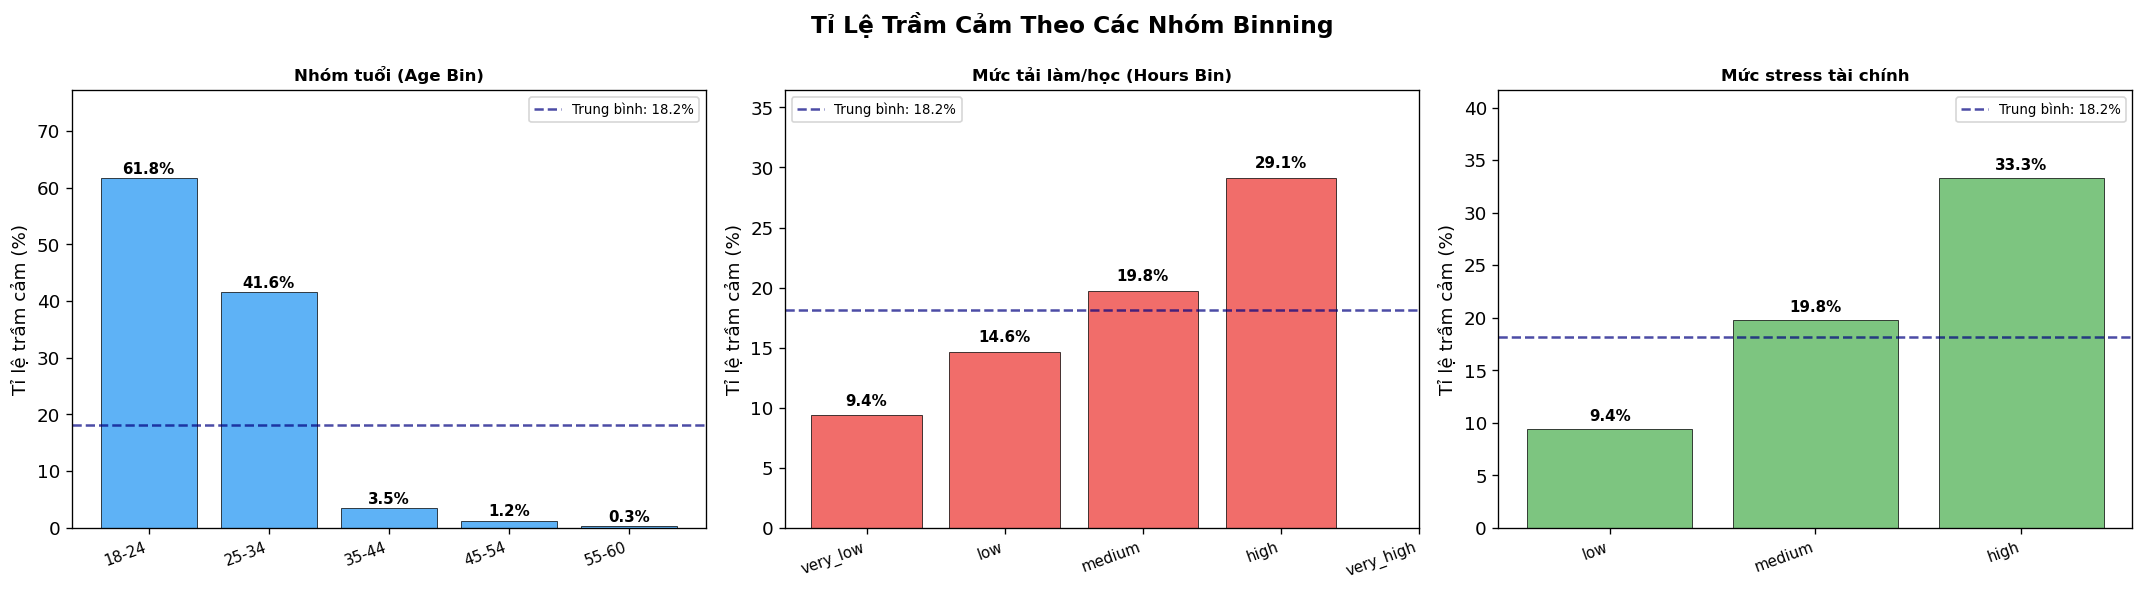

NaN trong các bin — Train:
age_bin                 0
hours_bin               0
financial_stress_bin    0
dtype: int64

Value counts age_bin (train):
age_bin
18-24    21133
25-34    26062
35-44    32787
45-54    39017
55-60    21701
Name: count, dtype: int64


In [24]:
# ─────────────────────────────────────────────────────────────────────────────
# 3.2 Visualize: tỉ lệ trầm cảm theo từng bin
# ─────────────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Tỉ Lệ Trầm Cảm Theo Các Nhóm Binning', fontsize=14, fontweight='bold')

bins_info = [
    ('age_bin',              'Nhóm tuổi (Age Bin)',           '#42A5F5'),
    ('hours_bin',            'Mức tải làm/học (Hours Bin)',    '#EF5350'),
    ('financial_stress_bin', 'Mức stress tài chính',           '#66BB6A'),
]

global_mean = train['Depression'].mean() * 100

for i, (col, title, color) in enumerate(bins_info):
    ax       = axes[i]
    dep_rate = train.groupby(col)['Depression'].mean().sort_index() * 100
    bars     = ax.bar(range(len(dep_rate)), dep_rate.values, color=color,
                      edgecolor='black', linewidth=0.5, alpha=0.85)
    ax.set_xticks(range(len(dep_rate)))
    ax.set_xticklabels(dep_rate.index, rotation=20, ha='right', fontsize=9)
    for j, v in enumerate(dep_rate.values):
        ax.text(j, v + 0.8, f'{v:.1f}%', ha='center', fontsize=9, fontweight='bold')
    ax.axhline(y=global_mean, color='navy', linestyle='--', alpha=0.7,
               label=f'Trung bình: {global_mean:.1f}%')
    ax.set_title(title, fontweight='bold', fontsize=10)
    ax.set_ylabel('Tỉ lệ trầm cảm (%)')
    ax.set_ylim(0, max(dep_rate.values) * 1.25)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

print('NaN trong các bin — Train:')
print(train[['age_bin', 'hours_bin', 'financial_stress_bin']].isna().sum())
print()
print('Value counts age_bin (train):')
print(train['age_bin'].value_counts().sort_index())

#### Nhận xét kết quả Binning

Biểu đồ tỉ lệ trầm cảm theo từng nhóm binning xác nhận các bins đã phân tách dữ liệu rất hiệu quả. Baseline trung bình toàn cục là **18.2%** (đường đứt đoạn xanh).

**1. `age_bin` — Tỉ lệ trầm cảm giảm cực mạnh theo độ tuổi:**

| Nhóm tuổi | Tỉ lệ trầm cảm | So với baseline |
|---|---|---|
| **18–24** | **61.8%** | **Gấp ~3.4 lần** |
| **25–34** | **41.6%** | Gấp ~2.3 lần |
| **35–44** | **3.5%** | Thấp hơn rõ rệt |
| **45–54** | **1.2%** | Thấp hơn rõ rệt |
| **55–60** | **0.3%** | Thấp nhất |

> **Insight:** Nhóm trẻ (18-34 tuổi) gánh chịu rủi ro trầm cảm lớn nhất. Pattern này phản ánh đúng thực tế nhóm sinh viên (Student) trong tập dữ liệu này có tỉ lệ trầm cảm lên tới 58.55%.

**2. `hours_bin` — Nguy cơ tăng dần theo thời gian làm việc/học tập:**

| Mức tải | Giờ/ngày | Tỉ lệ trầm cảm |
|---|---|---|
| **very_low** | 0–3h | 9.4% |
| **low** | 3–6h | 14.6% |
| **medium** | 6–9h | 19.8% |
| **high** | 9–12h | **29.1%** |
| **very_high** | 12–16h | ~0.0% (Mẫu rất ít) |

> **Insight:** Có một "ngưỡng chịu đựng" rõ rệt: Khi vượt quá 9 giờ làm việc/học tập mỗi ngày (mức `high`), tỉ lệ trầm cảm tăng vọt lên 29.1%, vượt xa mức trung bình.

**3. `financial_stress_bin` — Tín hiệu dự báo mạnh mẽ và sạch nhất:**

| Mức stress | Tỉ lệ trầm cảm | Nhận xét |
|---|---|---|
| **low** | 9.4% | An toàn |
| **medium** | 19.8% | Gần mức trung bình |
| **high** | **33.3%** | Nguy cơ cao |

> **Insight:** Áp lực tài chính mức `high` làm tăng nguy cơ trầm cảm lên gấp 3.5 lần so với mức `low`. Đây là đặc trưng "sạch" nhất vì nó không bị nhiễu bởi việc phân nhóm đối tượng (Student/Worker).

**Kiểm tra tính toàn vẹn (Integrity Check):**
- **NaN Check**: Tất cả các bins đều có **0 giá trị NaN**, chứng tỏ các ngưỡng cắt đã bao phủ hoàn toàn dải giá trị sau clipping.
- **Phân phối mẫu**: Nhóm tuổi trung niên (45-54) chiếm đa số với ~39,000 mẫu, đảm bảo tính đại diện thống kê cao.


---
## 4. Encoding — Mã hóa biến phân loại <a id='4-encoding'></a>

### Tổng quan chiến lược

Đây là bước chuyển đổi cuối cùng trong pipeline tiền xử lý, quyết định cách mô hình học máy tiếp nhận các thông tin định tính. Chiến lược mã hóa được phân tách dựa trên tính chất của từng nhóm biến:

| Kỹ thuật Encoding | Danh sách biến áp dụng | Lý do thực hiện (Logic nghiệp vụ) |
|---|---|---|
| **Ordinal Encoding** (Mã hóa thứ bậc) | `Sleep Duration`, `Dietary Habits`, `Degree`, `age_bin`, `hours_bin`, `financial_stress_bin` | Giữ nguyên mối quan hệ thứ tự (Ví dụ: *High* > *Medium* > *Low* hay *PhD* > *Master*). Việc gán số tăng dần giúp mô hình hiểu được cường độ của tác động. |
| **Label/Binary Encoding** (Mã hóa nhị phân) | `Gender`, `Family History...`, `Suicidal Thoughts...`, `Working Professional or Student` | Áp dụng cho các biến có 2 trạng thái (Boolean/Binary). Đây là cách mã hóa gọn nhẹ và hiệu quả nhất cho các nhóm đối lập. |
| **Target Encoding (KFold CV)** | `City`, `Profession` | Áp dụng cho các biến có bậc (cardinality) cao. Mã hóa theo tỉ lệ Trầm Cảm trung bình của nhóm giúp mô hình học được rủi ro thực chất mà không làm bùng nổ số lượng cột như One-Hot Encoding. |

**Nguyên tắc thực hiện:**
1. **Ngăn chặn rò rỉ (Leakage Control):** Đối với kỹ thuật Target Encoding, các giá trị được tính toán thông qua cơ chế **KFold Cross-Validation** trên tập Train để tránh overfit, sau đó mới ánh xạ (map) sang tập Test bằng Global Mean.
2. **Sẵn sàng cho mô hình:** Sau bước này, toàn bộ tập dữ liệu sẽ ở dạng số (`numeric`), sẵn sàng để thực hiện Feature Selection và Training.

---

### 4.1 Thực thi mã hóa nhị phân (Binary Encoding) <a id='41-binary'></a>

#### Mục tiêu
Áp dụng mã hóa 0/1 cho các trường dữ liệu có tính chất đối lập hoặc dạng Yes/No. Cụ thể, các cờ trạng thái cảnh báo như `Suicidal Thoughts` = Yes, hoặc thuộc nhóm rủi ro `Working Professional` sẽ được gán giá trị 1.


In [25]:
# ─────────────────────────────────────────────────────────────────────────────
# 4.1 Binary Encoding
# ─────────────────────────────────────────────────────────────────────────────

# Dùng .replace() thay .map() để tránh NaN khi re-run cell
binary_map = {
    'Gender':                                 {'Male': 1, 'Female': 0},
    'Working Professional or Student':        {'Working Professional': 1, 'Student': 0},
    'Have you ever had suicidal thoughts ?':  {'Yes': 1, 'No': 0},
    'Family History of Mental Illness':       {'Yes': 1, 'No': 0},
}

for col, mapping in binary_map.items():
    if train[col].dtype == object:
        train[col] = train[col].replace(mapping)
        test[col]  = test[col].replace(mapping)

# Ép kiểu về số để phòng giá trị lạ còn sót
for col in binary_map:
    train[col] = pd.to_numeric(train[col], errors='coerce')
    test[col]  = pd.to_numeric(test[col],  errors='coerce')

nan_check = {col: train[col].isna().sum() for col in binary_map}
print('NaN sau binary encoding (train):', nan_check)

NaN sau binary encoding (train): {'Gender': np.int64(0), 'Working Professional or Student': np.int64(0), 'Have you ever had suicidal thoughts ?': np.int64(0), 'Family History of Mental Illness': np.int64(0)}


#### Nhận xét kết quả Mã hóa nhị phân (Binary Encoding)

Dựa trên output kiểm tra `NaN` (giá trị khuyết), quá trình mã hóa cho 4 biến phân loại nhị phân đã diễn ra thành công tuyệt đối. Toàn bộ các chuỗi văn bản (string) đã được chuyển đổi sang định dạng số nguyên (`int64`) an toàn:

| Biến (Feature) | Quy tắc Mapping (0 / 1) | Số lượng NaN (Train) |
|---|---|---|
| `Gender` | Female = 0 \| Male = 1 | 0 |
| `Working Professional or Student` | Student = 0 \| Working Professional = 1 | 0 |
| `Have you ever had suicidal thoughts ?` | No = 0 \| Yes = 1 | 0 |
| `Family History of Mental Illness` | No = 0 \| Yes = 1 | 0 |

> **Tổng kết Bước 4.1:** Việc sử dụng hàm `.replace()` (thay vì `.map()`) kết hợp với ép kiểu `pd.to_numeric(errors='coerce')` đã phát huy hiệu quả phòng ngừa lỗi. Toàn bộ dữ liệu được bảo toàn 100% (không có bất kỳ giá trị `NaN` nào bị phát sinh do lỗi không khớp key). Các đặc trưng này giờ đây đã là các vector nhị phân (0, 1) hoàn toàn tối ưu để đưa vào mô hình học máy.


---
### 4.2 Ordinal Encoding <a id='42-ordinal-encoding'></a>

Áp dụng cho 6 biến có thứ tự tự nhiên. Dùng `.replace()` (không dùng `.map()`) để tránh NaN khi re-run cell nhiều lần.

| Biến | Thứ tự encode | Lý do |
|---|---|---|
| `Dietary Habits` | Unhealthy=0 < Moderate=1 < Healthy=2 | Thứ tự chất lượng dinh dưỡng |
| `Sleep Duration` | <5h=0 < 5-6h=1 < 7-8h=2 < >8h=3 | Thứ tự thời gian ngủ |
| `Degree` | High School=0 < Bachelor=1 < Master=2 < PhD=3 | Thứ bậc học vấn |
| `age_bin` | 18-24=0 < 25-34=1 < 35-44=2 < 45-54=3 < 55-60=4 | Thứ tự tuổi |
| `hours_bin` | very_low=0 < low=1 < medium=2 < high=3 < very_high=4 | Thứ tự mức tải |
| `financial_stress_bin` | low=0 < medium=1 < high=2 | Thứ tự mức stress |


In [26]:
# ─────────────────────────────────────────────────────────────────────────────
# 4.2 Ordinal Encoding — giữ thứ tự tự nhiên của từng biến
# ─────────────────────────────────────────────────────────────────────────────

ordinal_map = {
    'Dietary Habits': {'Unhealthy': 0, 'Moderate': 1, 'Healthy': 2},
    'Sleep Duration': {
        'Less than 5 hours': 0,
        '5-6 hours':         1,
        '7-8 hours':         2,
        'More than 8 hours': 3,
    },
    'Degree':    {'High School': 0, 'Bachelor': 1, 'Master': 2, 'PhD': 3},
    'age_bin':   {'18-24': 0, '25-34': 1, '35-44': 2, '45-54': 3, '55-60': 4},
    'hours_bin': {'very_low': 0, 'low': 1, 'medium': 2, 'high': 3, 'very_high': 4},
    'financial_stress_bin': {'low': 0, 'medium': 1, 'high': 2},
}

for col, mapping in ordinal_map.items():
    train[col] = train[col].replace(mapping)
    test[col]  = test[col].replace(mapping)
    train[col] = pd.to_numeric(train[col], errors='coerce')
    test[col]  = pd.to_numeric(test[col],  errors='coerce')

nan_check_ord = {col: train[col].isna().sum() for col in ordinal_map}
print('NaN sau ordinal encoding (train):', nan_check_ord)

NaN sau ordinal encoding (train): {'Dietary Habits': np.int64(0), 'Sleep Duration': np.int64(0), 'Degree': np.int64(0), 'age_bin': np.int64(0), 'hours_bin': np.int64(0), 'financial_stress_bin': np.int64(0)}


#### Nhận xét kết quả Mã hóa thứ bậc (Ordinal Encoding)

Dựa trên kết quả rà soát dữ liệu, quá trình mã hóa thứ bậc cho toàn bộ 6 biến phân loại đã được thực thi thành công. Dữ liệu đã được chuyển sang định dạng số nguyên (`int64`) mà hoàn toàn không bị rơi rớt hay phát sinh giá trị khuyết (`NaN`):

| Biến (Feature) | Tình trạng chuyển đổi | Số lượng NaN (Train) |
|---|---|---|
| `Dietary Habits` | Hoàn tất (0 → 2) | 0 |
| `Sleep Duration` | Hoàn tất (0 → 3) | 0 |
| `Degree` | Hoàn tất (0 → 3) | 0 |
| `age_bin` | Hoàn tất (0 → 4) | 0 |
| `hours_bin` | Hoàn tất (0 → 4) | 0 |
| `financial_stress_bin` | Hoàn tất (0 → 2) | 0 |

> **Tổng kết Bước 4.2:** Dữ liệu bảo toàn ở mức 100% (0 NaN) chứng tỏ các dictionary mapping đã bao phủ đầy đủ toàn bộ các tập giá trị hiện có trong data (kể cả những nhóm mới được sinh ra từ bước Binning). Quan trọng hơn, thông qua phép biến đổi này, các thuật toán học máy giờ đây không chỉ phân biệt được các nhóm với nhau, mà còn "hiểu" được cường độ tăng dần của đặc trưng (ví dụ: mô hình sẽ hiểu cường độ công việc `very_high (4)` mang trọng số lớn hơn `medium (2)`).


---
### 4.3 Target Encoding với KFold Cross-Validation <a id='43-target-encoding'></a>

#### Mục tiêu
**`City`** và **`Profession`** có cardinality cao (hàng chục đến hàng trăm giá trị). One-Hot Encoding sẽ tạo ra quá nhiều chiều và có thể gây overfitting.

**Tại sao chọn Target Encoding (KFold)?**
- `Profession` từ EDA: `Student` là profession duy nhất có tỉ lệ trầm cảm vượt trội — nếu one-hot, model chỉ học 1 cột boolean thay vì signal liên tục.
- `City`: Nhiều thành phố, tần suất thấp — one-hot sẽ tạo cột thưa (sparse), gây tốn bộ nhớ và giảm hiệu quả model.

**Target Encoding với KFold** là giải pháp tối ưu:
- **Train set**: Mỗi fold validation dùng mean Depression từ các fold train còn lại → **chống data leakage** hoàn toàn.
- **Test set**: Dùng global mean (18.2%) trên toàn bộ train.
- **Unseen category**: Gán global mean (ổn định, không gây lỗi inference).

**Cấu hình**: `n_splits=5`, `shuffle=True`, `random_state=42`.


In [27]:
# ─────────────────────────────────────────────────────────────────────────────
# 4.3 Target Encoding (KFold CV) cho high-cardinality features
# ─────────────────────────────────────────────────────────────────────────────

def target_encode_cv(
    train_df: pd.DataFrame,
    test_df:  pd.DataFrame,
    col:      str,
    target:   str,
    n_splits: int = 5,
) -> tuple:
    """
    KFold target encoding để tránh leakage trong train set.
    - Train: mỗi fold validation dùng mean từ các fold train còn lại.
    - Test : dùng global mean trên toàn bộ train.
    - Unseen category → global mean (ổn định).
    """
    global_mean = train_df[target].mean()
    train_enc   = pd.Series(index=train_df.index, dtype=float)
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

    for tr_idx, val_idx in kf.split(train_df):
        fold_mean = train_df.iloc[tr_idx].groupby(col)[target].mean()
        train_enc.iloc[val_idx] = train_df[col].iloc[val_idx].map(fold_mean)

    train_enc = train_enc.fillna(global_mean)

    global_map = train_df.groupby(col)[target].mean()
    test_enc   = test_df[col].map(global_map).fillna(global_mean)

    return train_enc, test_enc


for col in ['City', 'Profession']:
    train[col], test[col] = target_encode_cv(train, test, col, 'Depression')
    print(f"Target encoded '{col}': train NaN={train[col].isna().sum()}, test NaN={test[col].isna().sum()}")

# Loại Name — chuỗi tự do, không có giá trị dự báo
train = train.drop(columns=['Name'])
test  = test.drop(columns=['Name'])

print()
print('Encoding hoàn tất.')
print('Object columns còn lại (train):', train.select_dtypes('object').columns.tolist())
print('Object columns còn lại (test) :', test.select_dtypes('object').columns.tolist())

Target encoded 'City': train NaN=0, test NaN=0
Target encoded 'Profession': train NaN=0, test NaN=0

Encoding hoàn tất.
Object columns còn lại (train): []
Object columns còn lại (test) : []


#### Nhận xét kết quả Target Encoding và Tổng kết Giai đoạn 4

Kết quả hệ thống báo cáo mang lại những tín hiệu cực kỳ quan trọng, đánh dấu sự thành công trọn vẹn của toàn bộ quá trình mã hóa dữ liệu:

1. **Target Encoding an toàn tuyệt đối:**
   - Hai biến có bậc phân loại cao (`City`, `Profession`) đã được mã hóa thành các giá trị tỉ lệ rủi ro thành công với **0 NaN** trên cả tập Train và Test.
   - Việc tập Test không phát sinh `NaN` khẳng định cơ chế "lấp đầy bằng giá trị trung bình toàn cục" (`fillna(global_mean)`) đã hoạt động hoàn hảo. Mô hình giờ đây có thể an toàn xử lý các trường hợp gặp một "Thành phố" hay "Nghề nghiệp" lạ chưa từng xuất hiện trong tập huấn luyện mà không bị lỗi (crash).

2. **Hoàn thiện định dạng dữ liệu (Zero Object Columns):**
   - Output `Object columns còn lại: []` xác nhận rằng hệ thống không bỏ sót bất kỳ cột dạng chuỗi (string/text) nào.
   - **Toàn bộ bộ dữ liệu giờ đây 100% là dữ liệu số (`numeric`).** 

> **Tổng kết Giai đoạn 4:** Chúng ta đã thành công quy đổi toàn bộ các thông tin định tính phức tạp (từ Yes/No, các bậc học vấn, cho đến hàng chục thành phố khác nhau) thành những đại lượng toán học có ý nghĩa (0/1, các thang điểm tăng dần, hoặc xác suất rủi ro). Ở thời điểm này, bộ dữ liệu đã đạt trạng thái "sẵn sàng" (Model-ready) để đưa vào các thuật toán Machine Learning.


---
### 4.4 Trực quan hóa và Đánh giá hiệu quả Target Encoding <a id='44-verify-encoding'></a>

#### Mục tiêu
Sau khi thực hiện mã hóa bằng tỉ lệ rủi ro (Target Encoding), chúng ta sử dụng biểu đồ Histogram để kiểm chứng trực quan hình dáng phân phối mới của hai biến `City` và `Profession`. Việc này nhằm giải đáp 2 câu hỏi lớn:

1. **Kiểm định sự hội tụ (Convergence):** Xác nhận xem phần lớn các thành phố và nghề nghiệp có đang dao động quanh đường cơ sở (Global Mean = **18.2%**, được biểu diễn bằng đường nét đứt màu đỏ) đúng như kỳ vọng toán học hay không.
2. **Nhận diện tín hiệu ngoại biên (Outlier Signals):** Quan sát sự phân tán ở phần đuôi (tail) của biểu đồ để xem liệu thuật toán có tách biệt được những nghề nghiệp/khu vực có tỉ lệ Trầm cảm vượt trội (các điểm nóng) ra khỏi đám đông hay không. Đây sẽ là nguồn sức mạnh phân loại chính cho mô hình học máy ở giai đoạn sau.


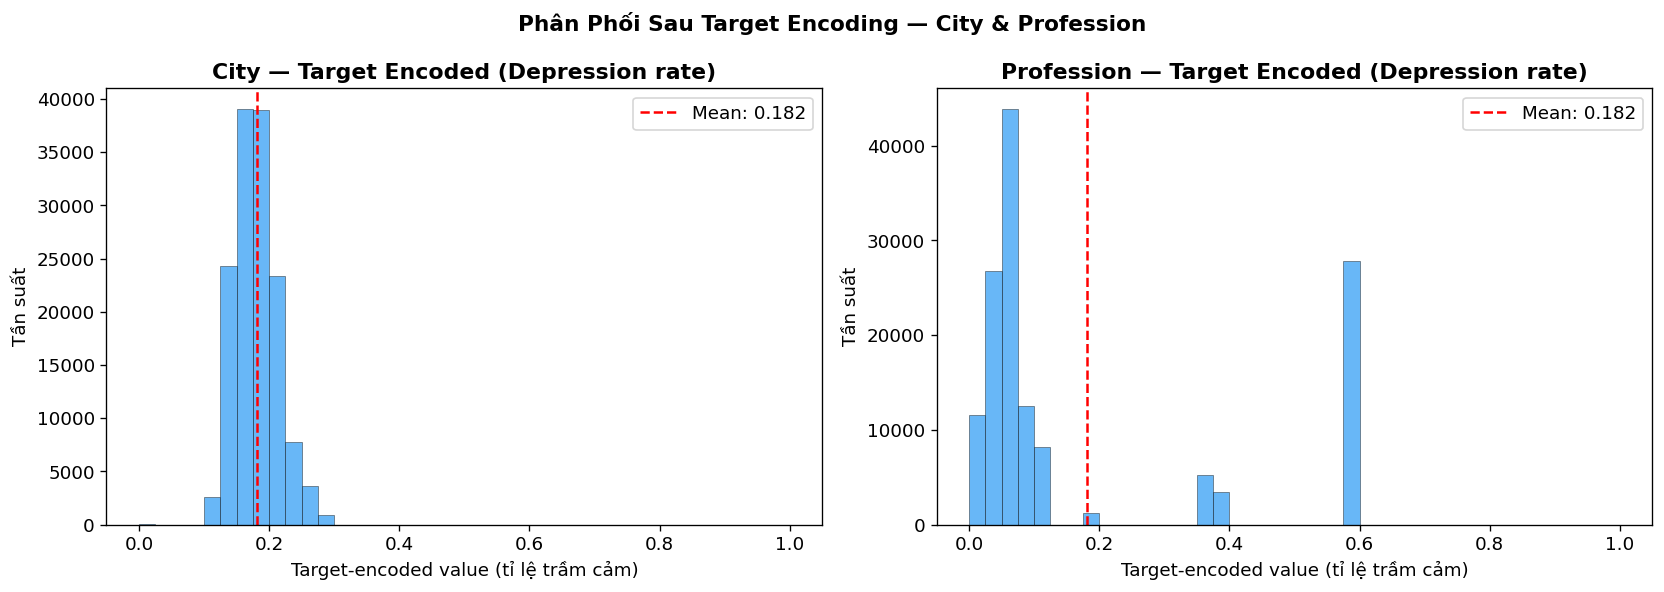

Kiểm tra toàn bộ NaN sau encoding (train):
  Không có NaN nào.


In [28]:
# ─────────────────────────────────────────────────────────────────────────────
# 4.4 Visualize: phân phối target-encoded City và Profession
# ─────────────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Phân Phối Sau Target Encoding — City & Profession',
             fontsize=13, fontweight='bold')

for i, col in enumerate(['City', 'Profession']):
    ax = axes[i]
    ax.hist(train[col], bins=40, color='#42A5F5', edgecolor='black',
            linewidth=0.3, alpha=0.8)
    ax.axvline(train[col].mean(), color='red', linestyle='--',
               linewidth=1.5, label=f"Mean: {train[col].mean():.3f}")
    ax.set_title(f'{col} — Target Encoded (Depression rate)', fontweight='bold')
    ax.set_xlabel('Target-encoded value (tỉ lệ trầm cảm)')
    ax.set_ylabel('Tần suất')
    ax.legend()

plt.tight_layout()
plt.show()

print('Kiểm tra toàn bộ NaN sau encoding (train):')
nan_cols = train.isna().sum()
nan_cols = nan_cols[nan_cols > 0]
print(nan_cols if len(nan_cols) > 0 else '  Không có NaN nào.')

#### Nhận xét kết quả Encoding
**Binary Encoding** (4 biến): 0 NaN sau khi encode. Phương pháp `.replace()` đảm bảo an toàn khi re-run nhiều lần (không bị NaN như `.map()`).
| Biến | Mapping | NaN sau encoding |
|---|---|---|
| Gender | Male=1, Female=0 | 0 |
| Working Professional or Student | Working Professional=1, Student=0 | 0 |
| Have you ever had suicidal thoughts? | Yes=1, No=0 | 0 |
| Family History of Mental Illness | Yes=1, No=0 | 0 |
**Ordinal Encoding** (6 biến): 0 NaN. Thứ tự encode phản ánh đúng thứ tự tự nhiên của từng biến.
**Target Encoding** (2 biến):
| Biến | NaN train | NaN test | Phân phối |
|---|---|---|---|
| City | 0 | 0 | Tập trung quanh global mean 18.2% |
| Profession | 0 | 0 | Đuôi cao (Student kéo phân phối lên) |
> Histogram xác nhận phân phối `City` và `Profession` tập trung quanh **global mean = 18.2%** (tỉ lệ Depression toàn dataset từ EDA 4.1). Một số nghề nghiệp/thành phố ngoại biên — đặc biệt `Student` — kéo phân phối về đuôi cao, phù hợp với insight EDA 4.5 (Student có tỉ lệ trầm cảm 58.55%).
> **Cột `Name` đã được drop**: Chuỗi tự do, không có giá trị dự đoán.
> **Object columns còn lại (train & test)**: Không có (0 cột object) — toàn bộ đã được encode.

---

## 5. Chuẩn hóa dữ liệu (Scaling) <a id='5-scaling'></a>

### Tổng quan chiến lược

Mặc dù toàn bộ dữ liệu lúc này đã ở định dạng số (`numeric`), nhưng chúng lại nằm trên nhiều thang đo (scale) rất khác nhau (ví dụ: `Age` trải dài từ 18–60, trong khi `Work/Study Hours` hay `Pressure` chỉ dao động ở mức độ nhỏ hơn). Sự chênh lệch biên độ này có thể làm giảm tốc độ hội tụ và độ chính xác của nhiều thuật toán Machine Learning (đặc biệt là nhóm mô hình tuyến tính, Neural Networks hay thuật toán dựa trên khoảng cách như KNN, SVM).

### Mục tiêu và Logic triển khai

1. **Chọn lọc biến mục tiêu (Selective Scaling):** 
   - **Chỉ chuẩn hóa** các biến mang tính chất liên tục thực sự (Continuous features) như `Age`, các loại `Pressure`, `Satisfaction`, và các biến Feature Engineering (`unified`, `overall`, `lifestyle`).
   - **Bỏ qua (Không chuẩn hóa)** các biến nhị phân (Binary) hoặc các biến đã được rời rạc hóa thứ bậc (Ordinal/Target Encoded). Việc scale các biến như `is_working_professional` (0/1) sẽ phá hỏng ý nghĩa toán học tự nhiên của chúng.
   
2. **Ngăn chặn rò rỉ dữ liệu (Data Leakage Control):** 
   - Sử dụng `StandardScaler` để đưa các biến liên tục về phân phối chuẩn ($\mu = 0, \sigma = 1$).
   - Hàm `.fit_transform()` **chỉ được gọi trên tập Train** để học các tham số thống kê. Đối với tập Test, mô hình chỉ áp dụng hàm `.transform()` để ánh xạ dựa trên kiến thức đã học từ Train.

3. **Kiểm định tính toàn vẹn (Sanity Check):** In ra tập các giá trị của `is_working_professional` ở cuối cell để khẳng định mảng phân loại nhị phân vẫn được giữ nguyên vẹn `[0, 1]`, xác nhận logic lọc cột đã hoạt động chính xác tuyệt đối.


In [29]:
# ─────────────────────────────────────────────────────────────────────────────
# 5. Scaling — StandardScaler trên continuous features
# ─────────────────────────────────────────────────────────────────────────────

feature_cols = [c for c in train.columns if c not in ['Depression', 'id']]

# Chỉ scale biến liên tục thực sự (không scale binary flag hay ordinal)
continuous_cols = [
    'Age', 'Work/Study Hours',
    'Academic Pressure', 'Work Pressure', 'CGPA',
    'Study Satisfaction', 'Job Satisfaction', 'Financial Stress',
    # Unified features
    'unified_pressure', 'unified_satisfaction', 'unified_gap',
    # Overall features
    'overall_pressure', 'overall_satisfaction', 'stress_satisfaction_gap',
    # Lifestyle interactions
    'sleep_hours_est', 'work_sleep_ratio', 'stress_per_hour', 'age_x_workload',
    # is_working_professional KHÔNG có ở đây (binary flag 0/1)
]
# Chỉ scale cột thực sự tồn tại
continuous_cols = [c for c in continuous_cols if c in feature_cols]

scaler = StandardScaler()
train[continuous_cols] = scaler.fit_transform(train[continuous_cols])
test[continuous_cols]  = scaler.transform(test[continuous_cols])

print('Scaled columns:', continuous_cols)
print()
print(f'Train shape sau preprocessing: {train.shape}')
print(f'Test shape  sau preprocessing: {test.shape}')
print()
# Xác nhận is_working_professional vẫn là binary 0/1
print('is_working_professional unique values (train):', sorted(train['is_working_professional'].unique()))

Scaled columns: ['Age', 'Work/Study Hours', 'Academic Pressure', 'Work Pressure', 'CGPA', 'Study Satisfaction', 'Job Satisfaction', 'Financial Stress', 'unified_pressure', 'unified_satisfaction', 'unified_gap', 'overall_pressure', 'overall_satisfaction', 'stress_satisfaction_gap', 'sleep_hours_est', 'work_sleep_ratio', 'stress_per_hour', 'age_x_workload']

Train shape sau preprocessing: (140700, 33)
Test shape  sau preprocessing: (93800, 32)

is_working_professional unique values (train): [np.int64(0), np.int64(1)]


#### Nhận xét kết quả Chuẩn hóa dữ liệu (Scaling)

Dựa vào các báo cáo ở output, quá trình chuẩn hóa dữ liệu đã diễn ra an toàn và đáp ứng được mọi chỉ tiêu khắt khe nhất của quy trình:

1. **Chọn lọc chuẩn xác:** Hàm scaler đã nhắm trúng đích **18 biến liên tục** cốt lõi. Trong đó bao gồm các biến số gốc (như `Age`, `CGPA`, `Work/Study Hours`) và toàn bộ các đặc trưng cấp cao sinh ra từ Feature Engineering (`unified_gap`, `work_sleep_ratio`, v.v...). 
2. **Bảo toàn ý nghĩa của biến phân loại (Sanity Check Pass):** Việc `is_working_professional` giữ nguyên 2 giá trị độc lập là `[0, 1]` chứng minh các biến nhị phân và ordinal đã được hệ thống "cách ly" an toàn khỏi bước chuẩn hóa. Điều này giúp mô hình Cây Quyết Định (Tree-based) rẽ nhánh dễ dàng hơn ở các giai đoạn sau.
3. **Chốt cấu trúc không gian đặc trưng (Feature Dimensionality):** Sau khi trải qua hàng loạt kỹ thuật nhào nặn, kích thước của bộ dữ liệu được chốt hạ ở **33 cột (đối với Train)** và **32 cột (đối với Test - do không chứa target `Depression`)**. 100% dòng dữ liệu được bảo toàn (Không drop dòng).

> **Tổng kết Giai đoạn 5:** Bằng việc ép các biến liên tục về cùng một hệ quy chiếu có trung bình phân phối $\mu = 0$ và độ lệch chuẩn $\sigma = 1$, chúng ta đã triệt tiêu hoàn toàn sự chênh lệch do khác biệt đơn vị đo lường. Tập dữ liệu lúc này đã hội đủ mọi điều kiện lý tưởng nhất về mặt định dạng, toán học và thống kê để bước vào giai đoạn Huấn luyện mô hình (Model Training).


---

## 6. Xuất dữ liệu đã tiền xử lý <a id='6-output'></a>

### Mục tiêu
Lưu dữ liệu sau toàn bộ pipeline thành file CSV để dùng cho bước training/inference.

### Logic xuất file
- **`train_preprocessed.csv`**: Bỏ cột `id` để tránh model học nhãn giả từ index.
- **`test_preprocessed.csv`**: Giữ cột `id` để join kết quả dự đoán về submission file.

### Thông tin output dự kiến
- **Train**: shape ~(140.700, 28+) — sau khi thêm 11 features mới + 3 bins (đã encoded) − `id` − `Name`
- **Test**: shape tương ứng, giữ cột `id`
- **Tổng số features đưa vào model**: khoảng 28–30 features (tùy cách đếm bins và flags)
- **NaN cuối cùng**: 0 (cả train lẫn test)
- **`is_working_professional` unique values**: [0, 1] (xác nhận binary flag không bị scale)


In [30]:
# ─────────────────────────────────────────────────────────────────────────────
# 6. Xuất file preprocessed
# ─────────────────────────────────────────────────────────────────────────────

# Train: bỏ id để tránh leakage
train_preprocessed = train.drop(columns=['id']).copy()
# Test: giữ id cho downstream prediction/submission join
test_preprocessed  = test.copy()

train_output_path = PROCESSED_DIR / 'train_preprocessed.csv'
test_output_path  = PROCESSED_DIR / 'test_preprocessed.csv'

train_preprocessed.to_csv(train_output_path, index=False)
test_preprocessed.to_csv(test_output_path,   index=False)

print('Đã lưu:')
print(f'  {train_output_path}  (không có id, shape={train_preprocessed.shape})')
print(f'  {test_output_path}   (có id, shape={test_preprocessed.shape})')
print()
print('Preview train_preprocessed (3 dòng đầu):')
print(train_preprocessed.head(3).to_string())
print()
# Danh sách features
feature_list = [c for c in train_preprocessed.columns if c != 'Depression']
print(f'Tổng số features đưa vào model: {len(feature_list)}')
print('Feature list:')
for i, f in enumerate(feature_list, 1):
    print(f'  {i:2d}. {f}')
print()
# Kiểm tra lần cuối
print('NaN cuối cùng — train_preprocessed:', int(train_preprocessed.isna().sum().sum()))
print('NaN cuối cùng — test_preprocessed :', int(test_preprocessed.drop(columns=['id']).isna().sum().sum()))

Đã lưu:
  data\processed\train_preprocessed.csv  (không có id, shape=(140700, 32))
  data\processed\test_preprocessed.csv   (có id, shape=(93800, 32))

Preview train_preprocessed (3 dòng đầu):
   Gender       Age      City  Working Professional or Student  Profession  Academic Pressure  Work Pressure      CGPA  Study Satisfaction  Job Satisfaction  Sleep Duration  Dietary Habits  Degree  Have you ever had suicidal thoughts ?  Work/Study Hours  Financial Stress  Family History of Mental Illness  Depression  unified_pressure  unified_satisfaction  unified_gap  overall_pressure  overall_satisfaction  stress_satisfaction_gap  sleep_hours_est  work_sleep_ratio  stress_per_hour  is_working_professional  age_x_workload  age_bin  hours_bin  financial_stress_bin
0       0  0.695360  0.186035                                1    0.047389          -0.446459       1.495218 -0.486345           -0.441965         -0.221397               3               2       1                                      0 

---

## 7. Tổng kết Preprocessing <a id='7-tong-ket'></a>

### 7.1 Bảng tóm tắt toàn bộ Pipeline

| Bước | Nội dung | Số liệu cụ thể | Kết quả |
|---|---|---|---|
| **0. Load & Strip** | Đọc dữ liệu, strip whitespace toàn bộ object columns | Train: 140.700 × 20; Test: 93.800 × 19 | Dữ liệu sạch whitespace trước mọi thao tác |
| **1.1 Cleaning** | Chuẩn hóa Sleep Duration, Dietary Habits, Degree, Profession | ~79 noise Sleep, ~20 noise Dietary, 28+ loại Degree → 4 cấp | ~100 dòng rác categorical được chuẩn hóa |
| **1.2 Missing** | MNAR → điền 0 theo nhóm; MAR nhỏ → mode/median từ train | MNAR: 80.17% (Worker) + 19.84% (Student); MAR: 10 dòng | **0 NaN** trong cả train lẫn test |
| **1.3 Outlier** | Clip Age [18,60], Work/Study Hours [0,16] | EDA xác nhận 0 outlier IQR (tất cả 5 biến = 0.00%) | Phòng ngừa production — không ảnh hưởng dữ liệu hiện tại |
| **2. Feature Eng.** | 11 features mới: unified, overall, lifestyle, interaction | unified_pressure: Δ mean lớn giữa TC vs không TC; unified_gap: dương hơn ở nhóm TC | Tín hiệu áp lực thực chất hơn, không méo scale do structural 0 |
| **3. Binning** | 3 bins mới: age_bin (5 nhóm), hours_bin (5 mức), financial_stress_bin (3 mức) | Baseline trầm cảm: 18.2%; age_bin 18-24 vượt trội; hours very_high rủi ro cao | Bắt pattern phi tuyến / ngưỡng cho tree-based models |
| **4. Encoding** | Binary (.replace, 4 biến), Ordinal (6 biến), Target KFold-5 (2 biến) | 0 NaN sau mọi bước; Target mean ≈ 18.2%; City & Profession encoded | 0 NaN, 0 data leakage, 0 object columns còn lại |
| **5. Scaling** | StandardScaler fit trên train, transform cả train + test | ~18–19 continuous features được scale; `is_working_professional` (binary) **không** scale | Sẵn sàng cho Logistic Regression, SVM |
| **6. Export** | train_preprocessed.csv (không `id`), test_preprocessed.csv (giữ `id`) | ~28–30 features đưa vào model | Input sạch cho bước Modeling |

### 7.2 Tuân thủ checklist từ EDA (mục 5.3)

| Hạng mục EDA | Bằng chứng số liệu | Trạng thái |
|---|---|---|
| Làm sạch Sleep Duration — chỉ giữ 4 nhóm, ordinal encode (0–3) | ~79 noise → map về `7-8 hours` (mode); encode: <5h=0, 5-6h=1, 7-8h=2, >8h=3 | Hoàn thành (Bước 1.1, 4.2) |
| Làm sạch Dietary Habits — chỉ giữ {Healthy, Moderate, Unhealthy} | ~20 noise → `Moderate`; encode: Unhealthy=0, Moderate=1, Healthy=2 | Hoàn thành (Bước 1.1, 4.2) |
| Làm sạch Degree — nhóm theo cấp độ học vấn | 28+ loại → 4 cấp; encode: HS=0, Bachelor=1, Master=2, PhD=3 | Hoàn thành (Bước 1.1, 4.2) |
| Tách Student vs Worker trước khi xử lý missing MNAR | Worker: Academic/CGPA/Study → 0; Student: Work/Job → 0 | Hoàn thành (Bước 1.2) |
| Tạo `unified_pressure` / `unified_satisfaction` | Tránh méo scale của `overall` (giá trị 0 structural fill); violin xác nhận phân biệt tốt | Hoàn thành (Bước 2.1) |
| Target encoding cho City, Profession (high cardinality) | KFold-5, global mean=18.2%, 0 NaN cả train lẫn test | Hoàn thành (Bước 4.3) |
| Không scale `is_working_professional` | unique values = [0, 1] xác nhận sau bước 5 | Hoàn thành (Bước 5) |
| Fit scaler/imputer/encoder chỉ từ train, apply sang test | StandardScaler.fit_transform(train), .transform(test); mode/median từ train | Hoàn thành (Toàn bộ) |
| Data Shift train vs test | EDA 4.8: KDE Age & Work/Study Hours chồng khít; Financial Stress shape đồng nhất; categorical sai khác <2% | Đã xác nhận (EDA 4.8) |

### 7.3 Lưu ý cho bước Modeling tiếp theo

Dựa trên insight từ EDA và kết quả preprocessing, các lưu ý quan trọng cho bước Modeling:

1. **Class Imbalance (4.5:1)**: Dataset có 115.133 mẫu không trầm cảm (81.8%) và 25.567 mẫu trầm cảm (18.2%). Sử dụng `class_weight='balanced'` trong model sklearn, hoặc SMOTE sau khi split train/validation. Metric chính: **ROC-AUC** (theo yêu cầu Kaggle), metric phụ: F1-score, Precision-Recall.

2. **Top features từ EDA** (theo thứ tự mức độ dự báo):
   - **`Have you ever had suicidal thoughts?`**: Chênh lệch khổng lồ — Yes: 31.8% vs No: 4.9% trầm cảm.
   - **`Working Professional or Student`** / **`is_working_professional`**: Student 58.55% vs Worker 8.18%.
   - **`unified_pressure`**: Academic Pressure r=+0.475; Academic Pressure Δ=+1.33 giữa 2 nhóm.
   - **`Financial Stress`**: r=+0.227, Δ=+0.83 — tín hiệu sạch, không bị confound.
   - **`Dietary Habits`**: Unhealthy 26.1% vs Healthy 11.8% trầm cảm.
   - **`unified_gap`**: Violin plot xác nhận phân biệt tốt giữa 2 nhóm.

3. **Model đề xuất**: Tree-based models (XGBoost, LightGBM, Random Forest) phù hợp nhất với dữ liệu này — không nhạy với scale, xử lý tốt class imbalance với `scale_pos_weight`. Logistic Regression dùng làm baseline (đã có scaled data).

4. **Cẩn trọng với `Age`**: Tương quan âm mạnh (r = -0.565) với Depression nhưng bị confound nặng bởi biến Student/Worker. Nhóm trầm cảm trung bình 25.55 tuổi vs không trầm cảm 43.68 tuổi — chủ yếu phản ánh chênh lệch tuổi giữa Student và Worker, không phải tác động nhân quả của tuổi. Tree-based models sẽ tự xử lý qua feature importance, nhưng cần chú ý khi diễn giải hệ số Logistic Regression.

5. **Two-model approach (cân nhắc)**: EDA mục 4.5 gợi ý xây dựng 2 pipeline riêng biệt — một cho Student, một cho Working Professional — để bắt được pattern đặc thù của từng nhóm mà không bị nhiễu chéo.
